# 05 · Evaluación en test

**Propósito:** medir una sola vez, en el test (los últimos 13 bloques de cada artículo), el CatBoost global del nb 04 frente al seasonal naive, de dos formas: **a un paso** (el régimen del backtesting que exige la constitución) y **encadenado 13 bloques** (el uso en producción).

**Contexto (constitución 7.0.0):** el nb 03b deja los datasets (517 artículos), el nb 03c los hiperparámetros (prueba 43, WRMSSE 0,506 en el backtesting frente a 0,894 del seasonal naive) y el nb 04 el modelo entrenado con todo el train. En la ventana de backtesting el encadenado dio 0,742 (nb 04, Etapa 2). Aquí nada se busca, se elige ni se ajusta: el test solo se mide.

**Etapas** (el estado de cada una vive en `specs/001-abc-xyz-share-forecast/nb05-etapas.md`):

| # | Etapa |
|---|---|
| 0 | Decisiones y reglas |
| 1 | Carga y comprobaciones (orígenes del test y modelo del nb 04) |
| 2 | Pronósticos del test: a un paso, encadenado y seasonal naive |
| 3 | Métricas globales y por artículo, aceptación y artículos para revisar |
| 4 | Guardado y cierre |


## Etapa 0 · Decisiones y reglas

**Objetivo:** fijar qué hace este notebook y con qué reglas, antes de escribir código.

**Decisiones propuestas:**

| # | Decisión | Justificación |
|---|---|---|
| D1 | **Entradas, cargadas y no recalculadas (R5):** `data/interim/nb03b_datasets/` (`boosting_data`, `rmsse_scale`, manifiesto), `data/interim/nb03c_boosting/catboost_backtest.pkl` (hiperparámetros, variables) y `models/nb04_catboost/` (modelo final y `meta.json`). Se exige que el `meta.json` traiga las mismas variables e hiperparámetros que el 03c y la misma versión de CatBoost. | Principio VI: lo congelado se carga. Si algo cambió entre notebooks, aparece aquí y no en las métricas. |
| D2 | **Orígenes del test:** los 13 bloques de test de cada artículo se numeran 1 a 13 por posición (como los folds de la ventana); todo el train, ventana incluida, queda como fold 0. Se usan las mismas funciones del backtesting (`fold_masks`, `boosting_backtest`, `recursive_ratio_forecast`). | Mismo régimen que en el backtesting (Principio VI) y mismo código ya probado; la partición es por artículo, así que los orígenes se definen por posición y no por fecha. |
| D3 | **A un paso:** en cada uno de los 13 orígenes el CatBoost se reentrena con todo lo observado hasta ese origen (train + bloques de test anteriores, filas con objetivo), hiperparámetros congelados, semilla 42 y 6 hilos; pronostica el bloque siguiente. Unidades = unidades reales del bloque anterior × tasa. | Constitución, Principio VI: «en test se repite el régimen del backtesting». Usar los bloques de test anteriores al origen no es fuga: en ese origen ya se observaron. |
| D4 | **Encadenado (usuario, 2026-11-10):** un solo origen, el último bloque de train; con el modelo del nb 04 se pronostican los 13 bloques de test, recalculando rezagos y ventanas del ratio con lo pronosticado. Unidades = unidades reales del origen × producto de las tasas. **Comprobación:** el modelo del origen 1 de D3 (mismo train, misma semilla e hilos) debe ser igual al del nb 04; si no, el notebook se detiene. | Es un mes de producción (13 bloques desde el último real) y es comparable con la Etapa 2 del nb 04. La comprobación garantiza que se mide el modelo guardado. |
| D5 | **Línea base:** seasonal naive, ŷ_t = y_{t−13} (unidades) y r_{t−13} (tasa). Con 13 pasos o menos, y_{t−13} ya se conoce en el origen, así que es el **mismo pronóstico** para a un paso y encadenado. | Principio VII: única línea base. Se calcula con la serie real ya cargada (train + test), sin ajuste. |
| D6 | **Métricas:** WRMSSE (criterio), WAPE (secundaria) y MAE (diagnóstico), en unidades y en tasas, por segmento y por paso. Pesos: gasto en los últimos 13 bloques de train. Escala del RMSSE: en unidades, la del 03b; en tasas, la misma definición sobre la tasa de todo el train (como en el nb 04). Se miden los 13 bloques de los 517 artículos, incluidas las 10 filas con ratio tratado. | Principio VII. Pesos y escalas solo con train (R5). |
| D7 | **Aceptación (Principio VII):** el CatBoost a un paso debe tener un WRMSSE en unidades menor que el seasonal naive. El encadenado se reporta frente al mismo seasonal naive como medida de producción, sin umbral propio. | La constitución fija la aceptación en el régimen del backtesting; el encadenado no estaba en ella. |
| D8 | **Una sola evaluación:** ningún resultado del test cambia un parámetro, una variable ni el modelo. Las pruebas en seco solo comprueban la mecánica. | Principio VI: el test se evalúa una vez; un cambio posterior exige nueva versión y repetir desde train. |
| D9 | **Salidas (usuario):** `data/interim/nb05_test/` con `forecasts.parquet` (una fila por artículo y bloque de test: real, a un paso, encadenado y seasonal naive, en tasas y en unidades) `metrics.parquet` (por nivel, forma, segmento y paso) e `item_metrics.parquet` (errores por artículo y marcas de D11), con manifiesto (`save_tables`) y candado (`RERUN`/`OVERWRITE`). El nb 06 las carga sin volver a tocar el test. | Una sola medición persistida; el informe no recalcula. |
| D11 | **Resumen de errores (usuario, 2026-11-10):** global (por segmento y total, D6) y **por artículo** (RMSSE, WAPE y MAE, a un paso y encadenado, en unidades y tasas), sin comparar cada artículo con el seasonal naive. Un artículo se marca **para revisar** si (a) su RMSSE en unidades es atípico dentro de su segmento, o (b) empeoró respecto de su backtesting: el cociente RMSSE test / RMSSE ventana es atípico dentro de su segmento. Atípico = mayor que Q3 + 1,5·IQR (regla de Tukey). Se hace por separado para a un paso (ventana del 03c, cargada) y encadenado (ventana encadenada con el modelo del fold 1, como en la Etapa 2 del nb 04). La tabla dice el motivo; en pantalla se grafican los marcados, hasta 5 por segmento (los de mayor RMSSE). | No hay selección contra el seasonal naive por artículo (constitución 7.0.0); el resumen sirve para ver qué artículos se alejan de lo esperado. Por segmento porque AZ tiene errores más altos por naturaleza. Tukey no fija un umbral a mano. El encadenado de la ventana no se guardó en el nb 04 y se repite con la misma función y el mismo modelo (determinista). |
| D10 | **Cómputo:** sin piloto (R7): 13 ajustes de ~3 s (el del nb 04 tardó 2,6 s con 24.348 filas) ≈ 40 s, más ~5 s del encadenado. | Tiempos ya medidos en el nb 04. |

**Reglas que se mantienen:** R1–R8 de `CLAUDE.md`.


## Configuración

**Qué hace:** fija la raíz del proyecto (rutas relativas), activa `%autoreload`, carga la configuración validada, fija la semilla e imprime las versiones (R6).


In [19]:
%load_ext autoreload
%autoreload 2

import os
import platform
import sys
from importlib.metadata import version
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import load_validated_config

pd.set_option("display.max_columns", 30)

cfg = load_validated_config()
SEED = cfg["features"]["seed"]

LIBS = ["numpy", "pandas", "pyarrow", "catboost"]
display(pd.Series({"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}}, name="versión").to_frame())
print(f"semilla: {SEED}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,versión
python,3.12.3
numpy,2.5.4
pandas,3.1.0
pyarrow,26.0.0
catboost,1.2.10


semilla: 42


## Candado

**Qué hace:** si las salidas del notebook ya existen, se detiene salvo `RERUN = True`; `OVERWRITE = True` solo para reemplazarlas (D8, D9).


In [20]:
from src.data import guard_rerun

OUT_DIR = Path("data/interim/nb05_test")   # D9: salida del notebook
RERUN = False       # True para volver a ejecutar aunque existan las salidas
OVERWRITE = False   # True solo para reemplazar lo guardado
guard_rerun([OUT_DIR / "manifest.json"], RERUN)


[]

## Etapa 1 · Carga y comprobaciones

**Objetivo:** tener en memoria lo congelado de los notebooks anteriores, numerar los orígenes del test y comprobar, antes de pronosticar nada, que lo que se va a medir es el modelo del nb 04 (D1, D2, D4).
**Entradas:**
- `data/interim/nb03b_datasets/` (nb 03b): `boosting_data`, `rmsse_scale` y el manifiesto.
- `data/interim/nb03c_boosting/catboost_backtest.pkl` (nb 03c): hiperparámetros y variables de la prueba 43.
- `models/nb04_catboost/` (nb 04): modelo final y `meta.json`.
- Gasto diario por artículo hasta el último día de train y el calendario, para los pesos del WRMSSE.

**Salidas:** `test_data` (dataset con `fold` 0 en train y 1–13 en test), `FEATURES`, `PARAMS`, `model04`, `meta04`, `rmsse_scale` y `weights`.
**Decisión:**
- Variables, hiperparámetros, semilla e hilos salen del `meta.json` del nb 04, y se exige que coincidan con el 03c, con el manifiesto del 03b y con la versión de CatBoost instalada.
- `assign_test_folds`: todo el train (ventana incluida) es fold 0 y el k-ésimo bloque de test de cada artículo es fold k; falla si el test de algún artículo no empieza justo después de su train.
- **Modelo del origen 1:** se entrena con las filas de fold 0 con objetivo (la regla de D3) y debe ser igual al del nb 04 (igualdad de CatBoost). Si no lo es, se detiene: el a un paso y el encadenado no estarían midiendo el mismo modelo. No se pronostica el test en esta etapa.
- Pesos del WRMSSE: gasto en los últimos 13 bloques de train, como en el nb 04 (Principio VII).


In [21]:
from src.config import train_end
from src.data import load_calendar, load_interim, load_tables
from src.features import BLOCK_DAYS
from src.metrics import spend_weights, train_weight_windows
from src.modeling import assign_test_folds, fold_masks, load_catboost_model, make_booster

DATASETS_DIR = Path("data/interim/nb03b_datasets")                         # nb 03b
CATBOOST_FILE = Path("data/interim/nb03c_boosting/catboost_backtest.pkl")  # nb 03c, prueba 43
MODEL_DIR = Path("models/nb04_catboost")                                   # nb 04
N_TEST = 13          # bloques de test por artículo (Principio VI)
WEIGHT_BLOCKS = 13   # pesos del WRMSSE: gasto en los últimos 13 bloques de train (Principio VII)


In [22]:
inputs, manifest = load_tables(DATASETS_DIR)
catboost = pd.read_pickle(CATBOOST_FILE)
model04, meta04 = load_catboost_model(MODEL_DIR)
boosting_data = inputs["boosting_data"]
rmsse_scale = inputs["rmsse_scale"].set_index("item_id")["scale"]
FEATURES, PARAMS = meta04["features"], meta04["params"]
N_THREADS = meta04["n_threads"]

test_data = assign_test_folds(boosting_data)

cal = load_calendar(cfg)
day_of = pd.Series(cal["d"].str[2:].astype(int).to_numpy(), index=pd.to_datetime(cal["date"]))   # fecha → día d
interim = load_interim(cfg, max_day=train_end(cfg))   # gasto diario solo hasta el último día de train
weights = spend_weights(interim["item_spend"], interim["item_ids"],
                        train_weight_windows(boosting_data, day_of, WEIGHT_BLOCKS, BLOCK_DAYS))

# Modelo del origen 1: mismas filas, semilla e hilos que el nb 04.
train1, _ = fold_masks(test_data, 1)
fit1 = train1 & test_data["ratio"].notna()
model_o1 = make_booster("catboost", PARAMS, meta04["seed"], N_THREADS)
model_o1.fit(test_data.loc[fit1, FEATURES], test_data.loc[fit1, "ratio"])


CatBoostRegressor(allow_writing_files=False, boosting_type='Plain', bootstrap_type='Bernoulli', border_count=64, cat_features=['item_id', 'cell', 'period'], depth=4, l2_leaf_reg=2.909726254047063, learning_rate=0.07105754327165416, loss_function='RMSE', n_estimators=450, random_seed=42, random_strength=0.1147831653251715, rsm=0.5024003667598801, subsample=0.7367534294846864, thread_count=6, verbose=0)

In [23]:
# Lo congelado coincide entre notebooks.
assert FEATURES == catboost["meta"]["features"] and PARAMS == catboost["meta"]["params"]
assert meta04["seed"] == SEED == catboost["meta"]["seed"]
assert meta04["versions"]["catboost"] == version("catboost") == catboost["meta"]["versions"]["catboost"]
assert meta04["source"]["nb03b_saved_at"] == manifest["saved_at"] and meta04["source"]["nb03c_trial"] == catboost["meta"]["trial"]

# Orígenes del test.
n_items = test_data["item_id"].nunique()
per_fold = test_data[test_data["split"] == "test"].groupby("fold").size()
assert (test_data.loc[test_data["split"] == "train", "fold"] == 0).all()
assert list(per_fold.index) == list(range(1, N_TEST + 1)) and (per_fold == n_items).all()
assert len(test_data) == len(boosting_data) and set(weights.index) == set(test_data["item_id"].astype(str))

# Modelo del origen 1 = modelo del nb 04 (D4).
assert fit1.sum() == meta04["fit"]["rows"]
assert model_o1 == model04, "el modelo del origen 1 no es el del nb 04"

print(f"nb 03b: {manifest['saved_at']} · nb 03c: prueba {catboost['meta']['trial']} · nb 04: {meta04['saved_at']} · CatBoost {version('catboost')}")
print(f"{n_items} artículos × {N_TEST} bloques de test; origen 1: {fit1.sum():,} filas de ajuste, modelo igual al del nb 04")
display(test_data.groupby("split")["fold"].agg(["min", "max", "count"]))


nb 03b: 2026-11-07T08:25:38 · nb 03c: prueba 43 · nb 04: 2026-11-09T18:55:45 · CatBoost 1.2.10
517 artículos × 13 bloques de test; origen 1: 24,348 filas de ajuste, modelo igual al del nb 04


,min,max,count
split,,,
test,1,13,6721
train,0,0,24443


## Etapa 2 · Pronósticos del test: a un paso, encadenado y seasonal naive

**Objetivo:** pronosticar los 13 bloques de test de los 517 artículos de las tres formas y dejarlos en una sola tabla (D3, D4, D5). Aquí no se mide nada: las métricas son de la Etapa 3.
**Entradas:** `test_data`, `FEATURES`, `PARAMS`, `model04` y `meta04` (Etapa 1); `target_lags`, `rolling_windows` y `rolling_stats` de `params.toml`.
**Salidas:** `forecasts`, una fila por artículo y bloque de test con lo real (`units`, `ratio_raw`) y, en tasas y en unidades, los pronósticos `*_1step`, `*_chain` y `*_snaive`; y el gráfico de cada artículo.

**Decisión:**
- **A un paso (D3):** `boosting_backtest` sobre `test_data`: en cada origen k reentrena con fold < k (todo el train y los bloques de test 1 a k − 1, filas con objetivo) y pronostica el bloque k. Unidades = unidades reales del bloque anterior × tasa. ~45 s.
- **Encadenado (D4):** `recursive_ratio_forecast` con `model04` desde el último bloque de train, 13 pasos; rezagos y ventanas del ratio recalculados con lo pronosticado. Unidades = unidades reales del origen × producto de las tasas (`chain_units`). ~8 s.
- **Seasonal naive (D5):** el valor real de 13 bloques antes (`seasonal_naive`, m = 13), en unidades y en tasa (`ratio_raw`). Una sola columna por nivel sirve para las dos formas.
- **Gráfico por artículo (usuario, 2026-11-10), igual al del nb 04:** arriba tasas, abajo unidades; toda la historia (train y test), el test sombreado, a un paso (naranja) y encadenado (azul) con su WAPE y RMSSE en el test; a la derecha el error de cada bloque. Escala del RMSSE: en unidades la del 03b; en tasas, la misma definición sobre la tasa de todo el train (como en el nb 04). Se muestran 5 artículos al azar por segmento (semilla) y se guardan los 517 en `reports/figures/nb05_test/<segmento>/<item_id>.png` (110 ppp; ~80 MB, ~6 min; se sobrescriben, no alimentan decisiones).
- **Chequeos:** 517 × 13 filas, una por artículo y bloque, sin nulos; en el paso 1 encadenado = a un paso (mismo modelo y mismas variables); unidades a un paso = anterior real × tasa; unidades encadenadas = paso anterior × tasa; seasonal naive = valor real del bloque − 13; cada artículo con su gráfico en la carpeta de su segmento.


In [24]:
import time

import matplotlib.pyplot as plt

from src.metrics import seasonal_naive_scale
from src.modeling import boosting_backtest, chain_units, plot_forecast_item, recursive_ratio_forecast, seasonal_naive

FE = cfg["features"]
SNAIVE_M = manifest["snaive_m"]   # 13 bloques: el mismo periodo del año anterior (Principio VII)
SEGMENTS = ["AX", "AY", "AZ"]
SAMPLE_PER_SEGMENT = 5                       # usuario, como en el nb 04
FIG_DIR = Path("reports/figures/nb05_test")  # reports/ es parte de la estructura fija (Principio III)
FIG_DPI = 110                                # se lee bien en pantalla y pesa poco


In [25]:
start = time.perf_counter()
one_step = boosting_backtest(test_data, FEATURES, "catboost", PARAMS, meta04["seed"], N_THREADS)
t_one = time.perf_counter() - start

start = time.perf_counter()
chain = recursive_ratio_forecast(test_data, model04, FEATURES, FE["target_lags"], FE["rolling_windows"],
                                 FE["rolling_stats"], first_fold=1, horizon=N_TEST)
t_chain = time.perf_counter() - start

# Seasonal naive en unidades y en tasa, con la serie real completa (D5).
series = test_data[["item_id", "block"]].assign(item_id=lambda d: d["item_id"].astype(str))
snaive_units = seasonal_naive(series.assign(units=test_data["units"]), SNAIVE_M)
snaive_ratio = seasonal_naive(series.assign(units=test_data["ratio_raw"]), SNAIVE_M)

# Una tabla: real + las tres formas, en tasas y en unidades.
test_rows = test_data["split"] == "test"
forecasts = (test_data.loc[test_rows, ["item_id", "block", "fold", "cell", "imputed", "ratio_treated", "units", "units_prev", "ratio_raw"]]
             .assign(item_id=lambda d: d["item_id"].astype(str), cell=lambda d: d["cell"].astype(str),
                     step=lambda d: d["fold"].astype(int), ratio_snaive=snaive_ratio[test_rows], units_snaive=snaive_units[test_rows])
             .drop(columns="fold")
             .merge(one_step[["item_id", "block", "ratio_hat", "pred"]].rename(columns={"ratio_hat": "ratio_1step", "pred": "units_1step"}),
                    on=["item_id", "block"], validate="one_to_one")
             .merge(chain[["item_id", "block", "ratio_hat"]].rename(columns={"ratio_hat": "ratio_chain"}),
                    on=["item_id", "block"], validate="one_to_one")
             .sort_values(["item_id", "block"], ignore_index=True))
origin_units = forecasts.loc[forecasts["step"] == 1].set_index("item_id")["units_prev"].astype(float)   # unidades reales del origen
forecasts["units_chain"] = chain_units(forecasts.rename(columns={"ratio_chain": "ratio_hat"}), origin_units)


In [26]:
FCST = [f"{lvl}_{kind}" for lvl in ("ratio", "units") for kind in ("1step", "chain", "snaive")]
assert len(forecasts) == n_items * N_TEST and not forecasts.duplicated(["item_id", "block"]).any()
assert forecasts[FCST + ["units", "ratio_raw"]].notna().all().all()
assert (forecasts.groupby("item_id")["step"].agg(["min", "max", "count"]) == [1, N_TEST, N_TEST]).all().all()

# Paso 1: nada encadenado, así que encadenado = a un paso.
s1 = forecasts[forecasts["step"] == 1]
assert np.array_equal(s1["ratio_chain"], s1["ratio_1step"]) and np.allclose(s1["units_chain"], s1["units_1step"])
# Unidades a un paso y encadenadas.
assert np.allclose(forecasts["units_1step"], forecasts["units_prev"] * forecasts["ratio_1step"])
prev_chain = forecasts.groupby("item_id")["units_chain"].shift(1).fillna(forecasts["units_prev"])
assert np.allclose(forecasts["units_chain"], prev_chain * forecasts["ratio_chain"])
# Seasonal naive = valor real 13 bloques antes.
lagged = forecasts[["item_id", "block"]].assign(block=lambda d: d["block"] - SNAIVE_M).merge(
    series.assign(units=test_data["units"], ratio_raw=test_data["ratio_raw"]), on=["item_id", "block"], how="left")
assert np.allclose(forecasts["units_snaive"], lagged["units"]) and np.allclose(forecasts["ratio_snaive"], lagged["ratio_raw"])

print(f"a un paso: {t_one:.0f} s (13 reentrenamientos) · encadenado: {t_chain:.0f} s · {len(forecasts):,} filas, "
      f"{forecasts['ratio_treated'].sum()} con ratio tratado (se miden igual, D6)")
display(forecasts[["item_id", "block", "step", "cell", "units", *[f"units_{k}" for k in ("1step", "chain", "snaive")],
                   "ratio_raw", *[f"ratio_{k}" for k in ("1step", "chain", "snaive")]]].sample(5, random_state=SEED))


a un paso: 31 s (13 reentrenamientos) · encadenado: 4 s · 6,721 filas, 10 con ratio tratado (se miden igual, D6)


,item_id,block,step,cell,units,units_1step,units_chain,units_snaive,ratio_raw,ratio_1step,ratio_chain,ratio_snaive
3552,FOODS_3_727,56,4,AY,768.500000,946.523900,785.512784,796.000000,0.779412,0.959963,0.964746,0.973190
4108,HOBBIES_1_100,53,1,AX,110.214286,106.261162,106.261162,95.000000,1.023889,0.987164,0.987164,0.959596
549,FOODS_2_022,56,4,AZ,384.285714,431.911375,551.851060,490.500000,0.950950,1.068804,1.035369,1.329140
1163,FOODS_2_322,59,7,AX,887.821429,839.859386,750.005005,791.000000,1.054107,0.997162,1.011315,1.126781
1881,FOODS_3_224,62,10,AZ,499.535714,437.254240,480.733407,514.428571,1.251857,1.095777,1.020391,1.019031


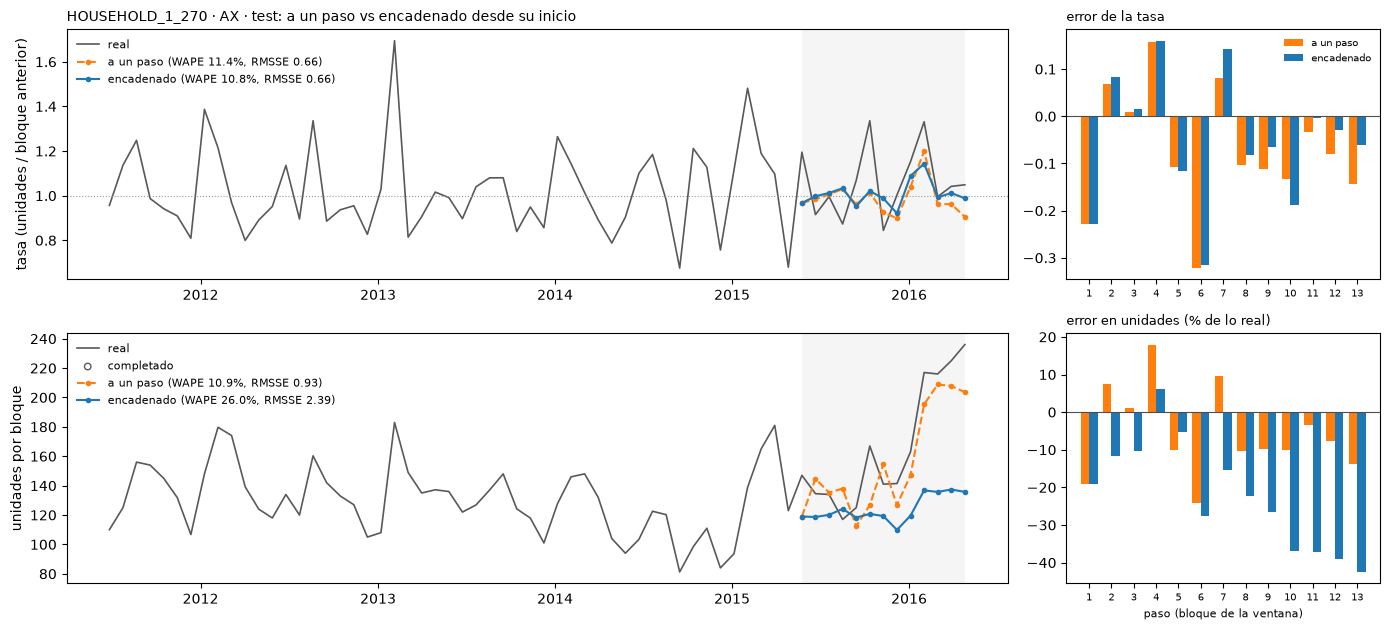

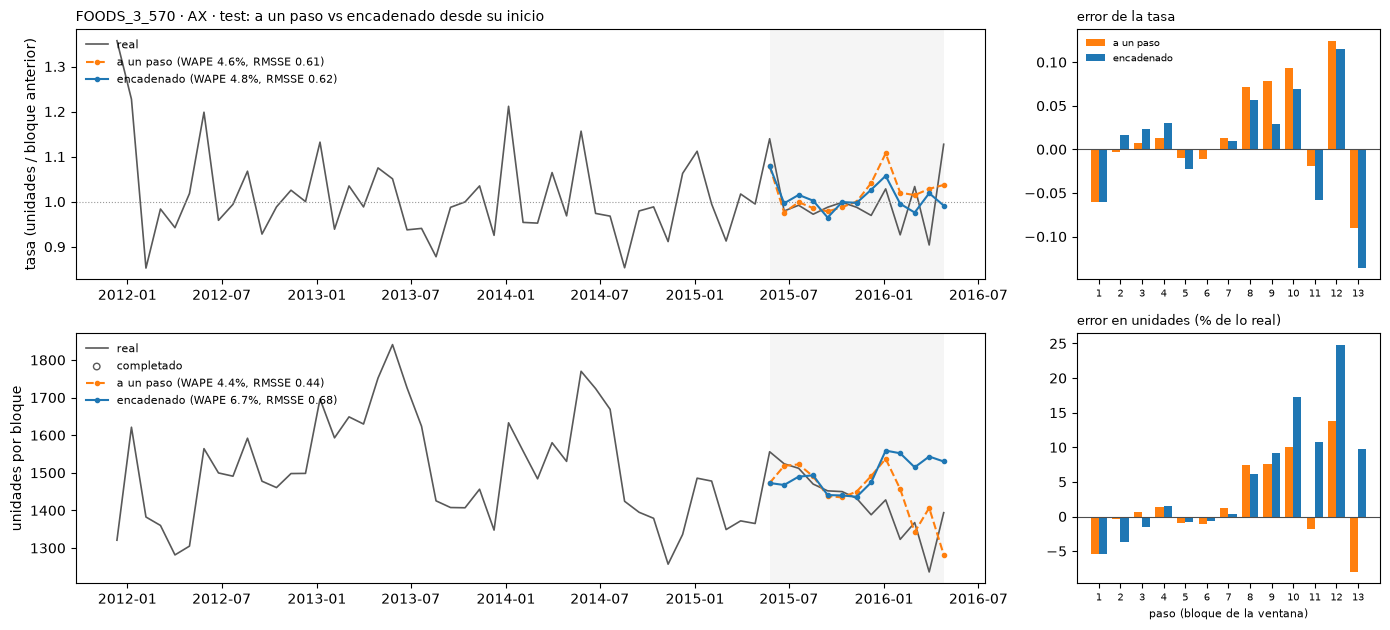

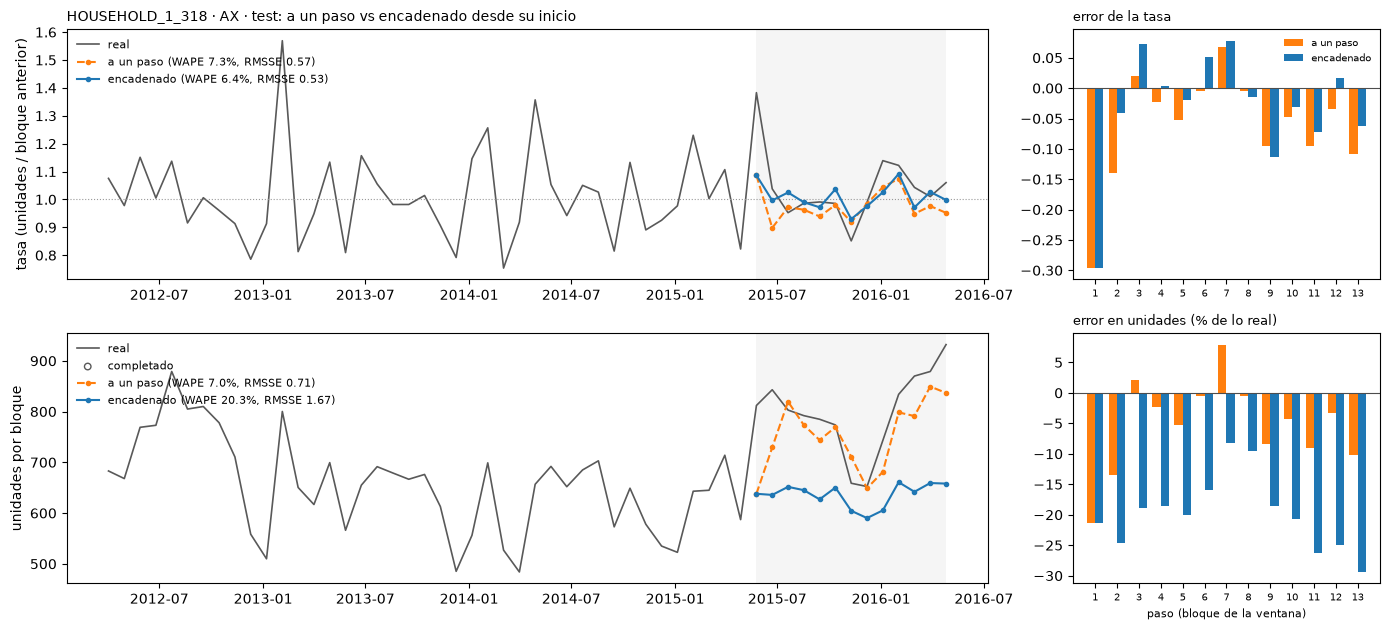

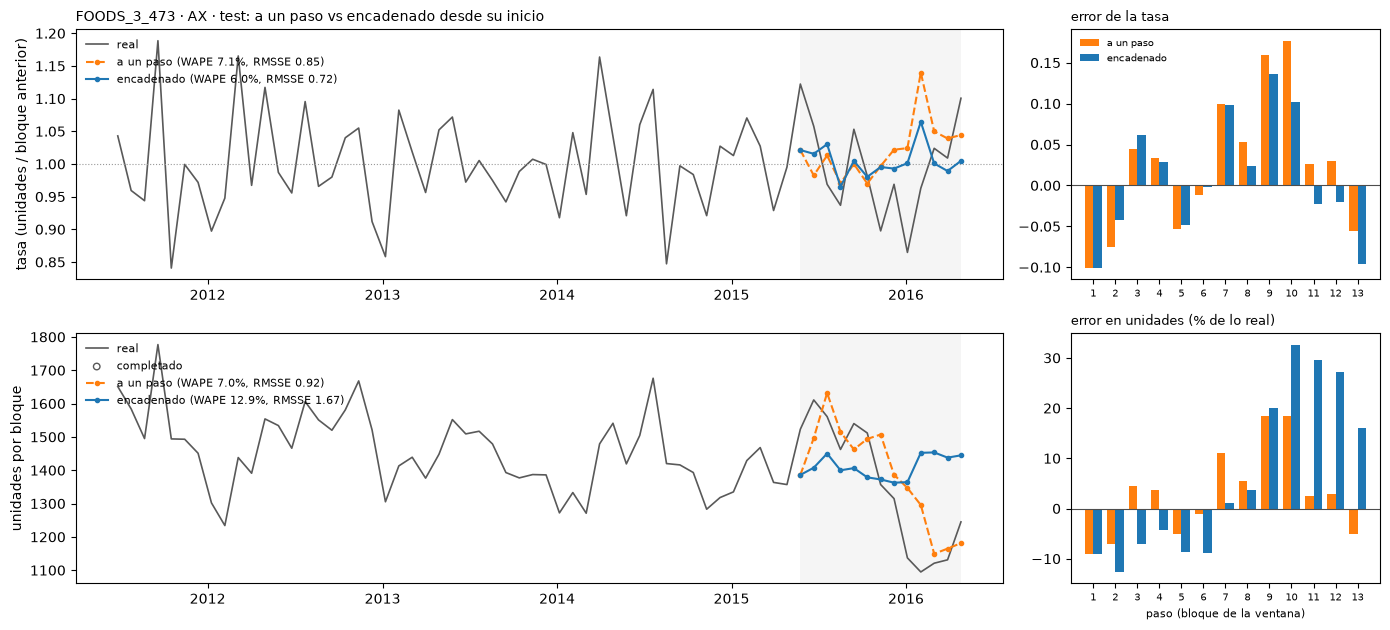

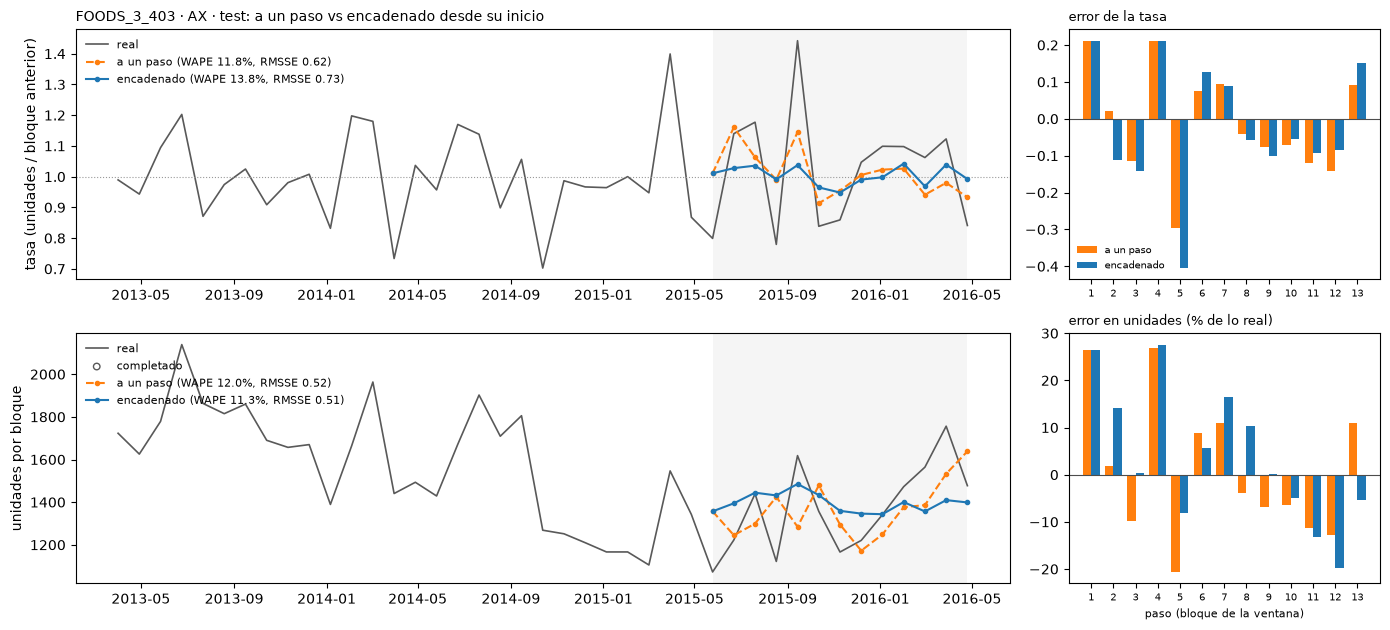

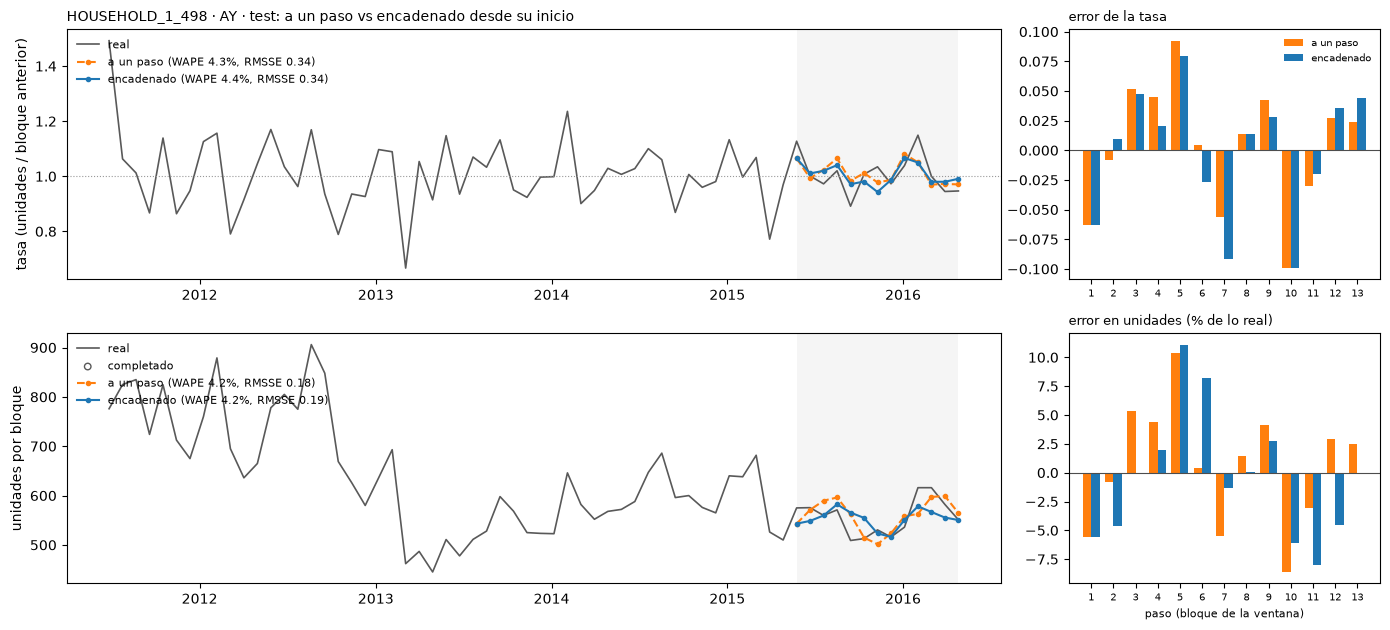

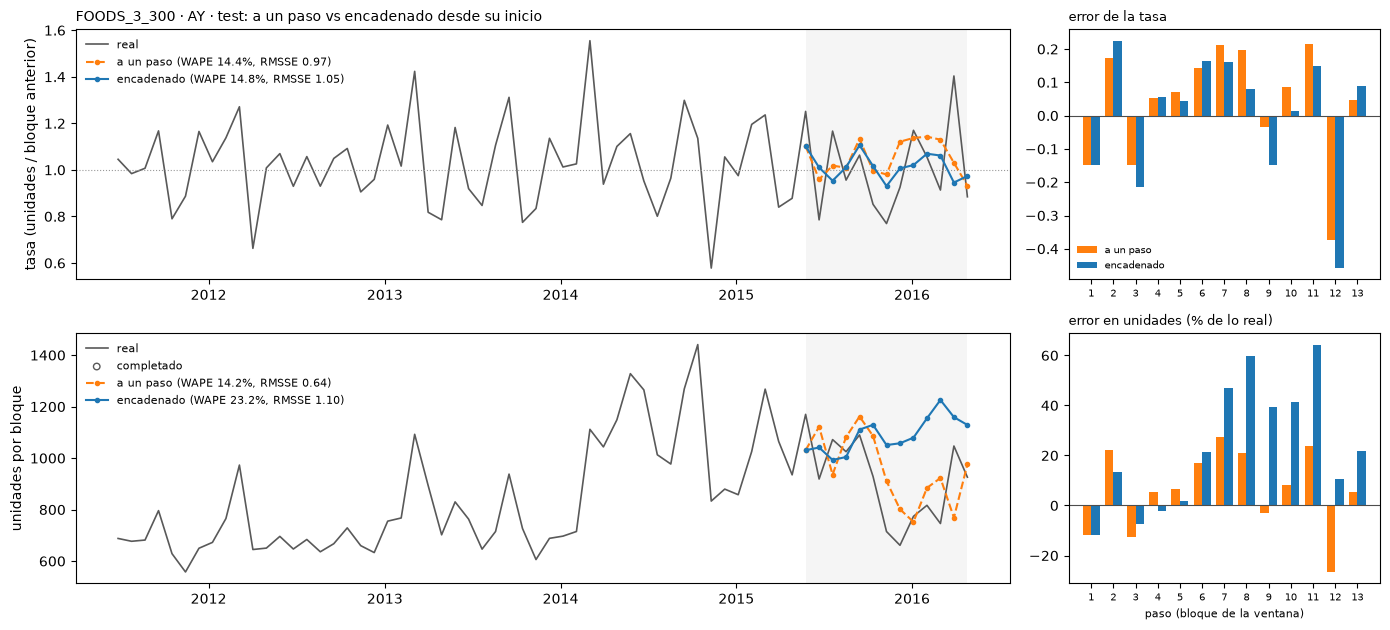

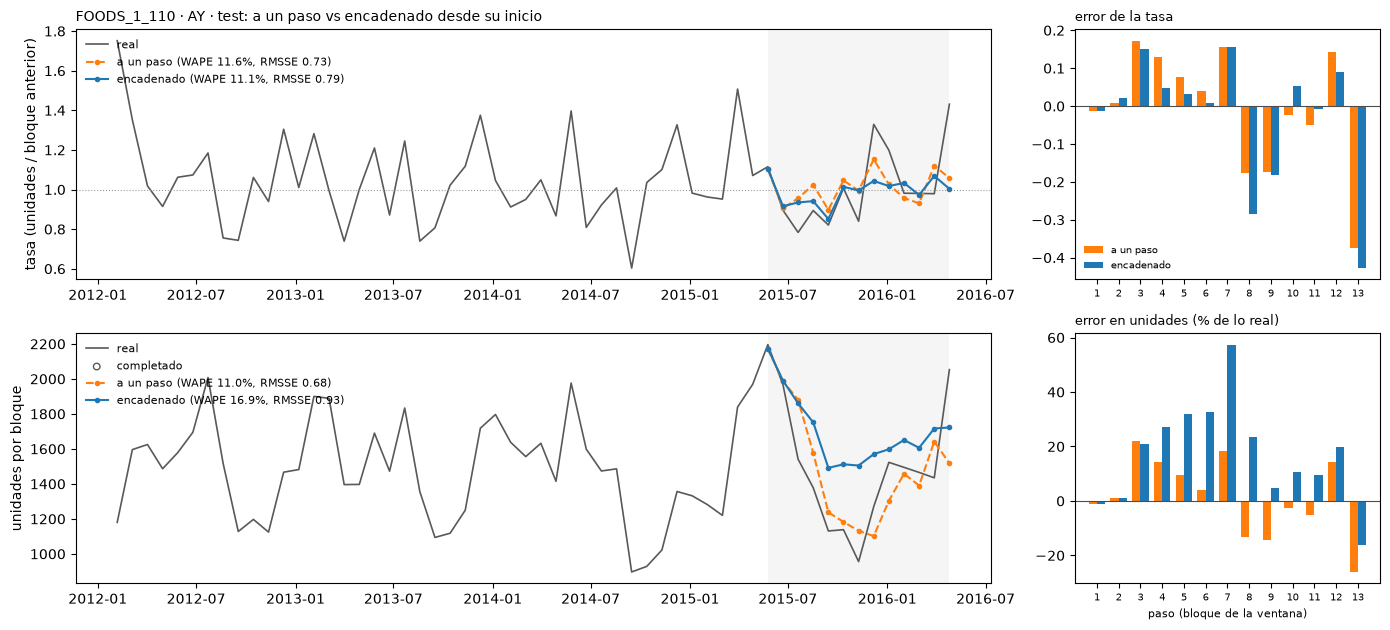

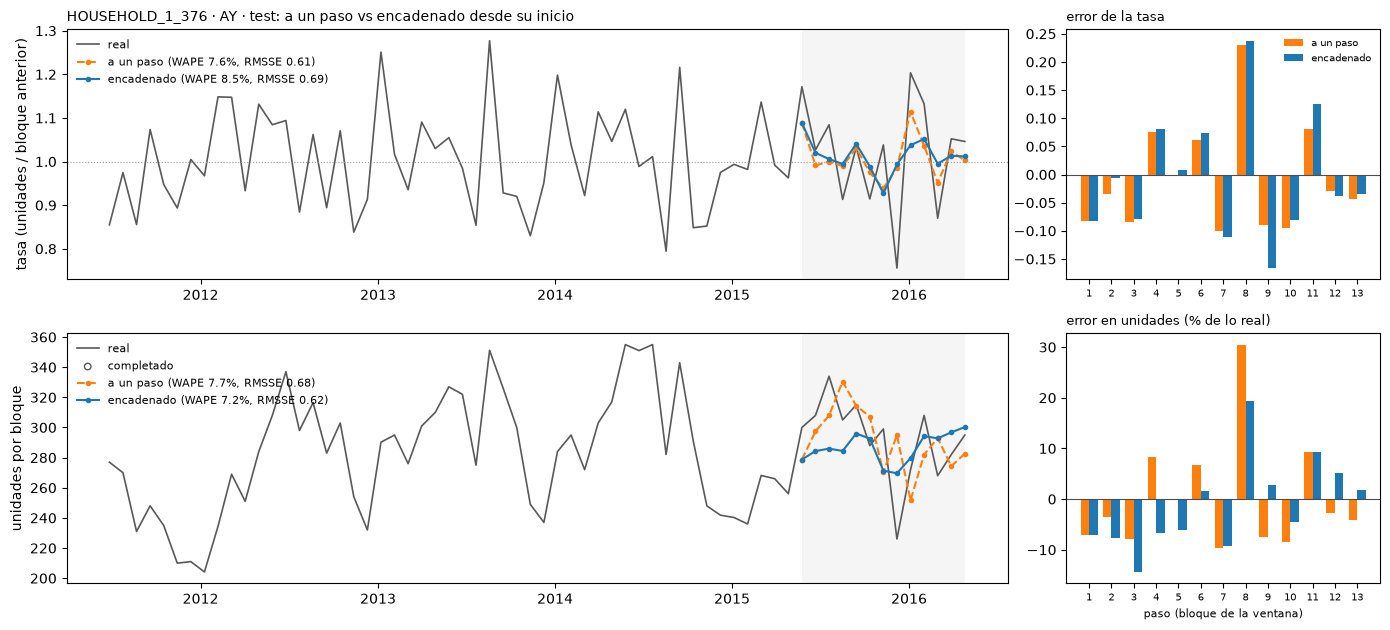

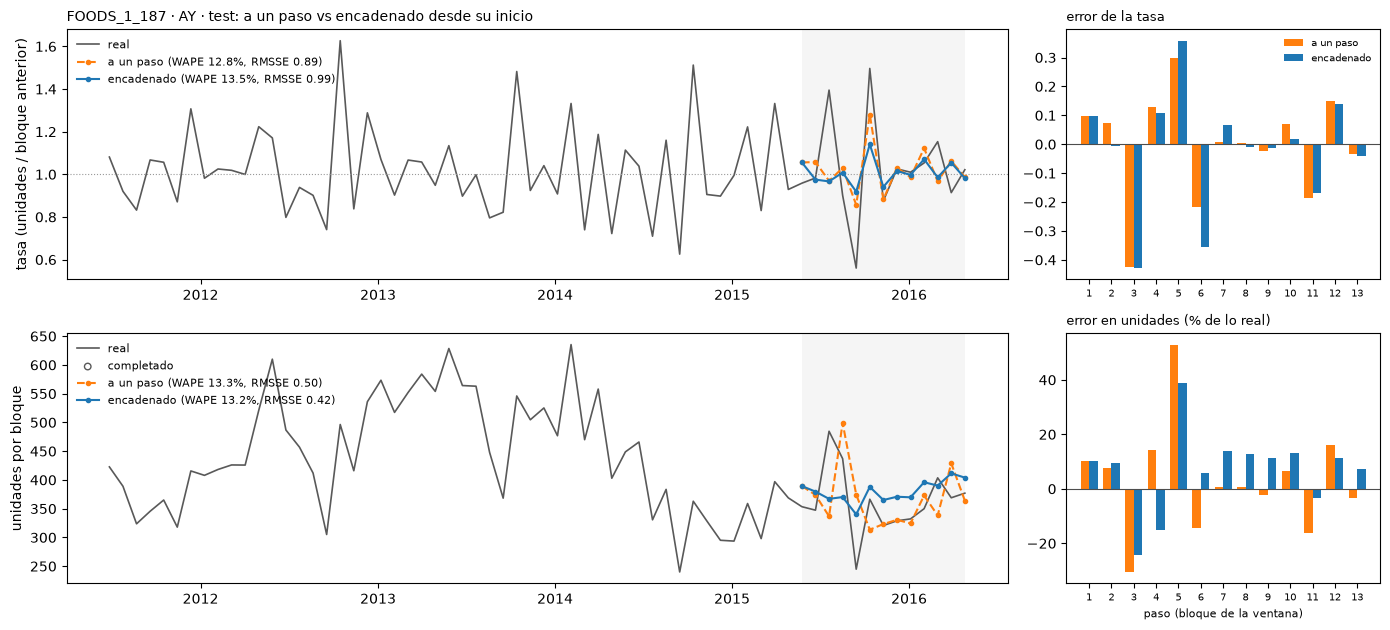

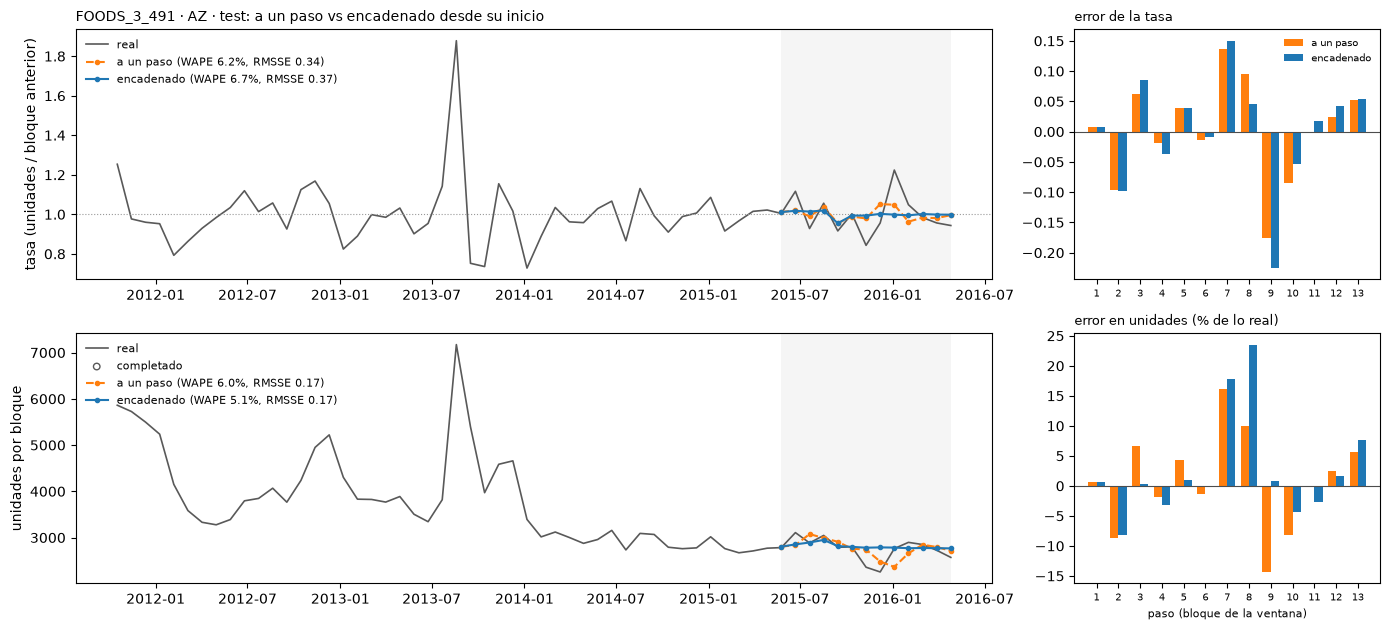

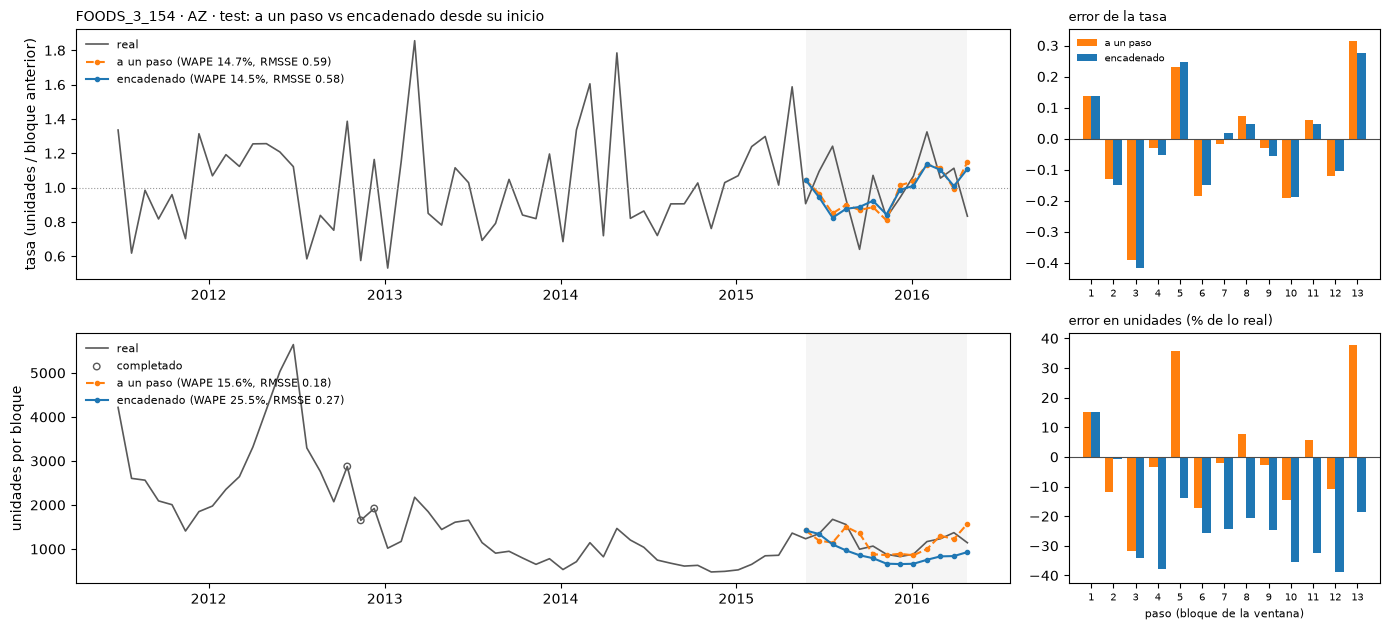

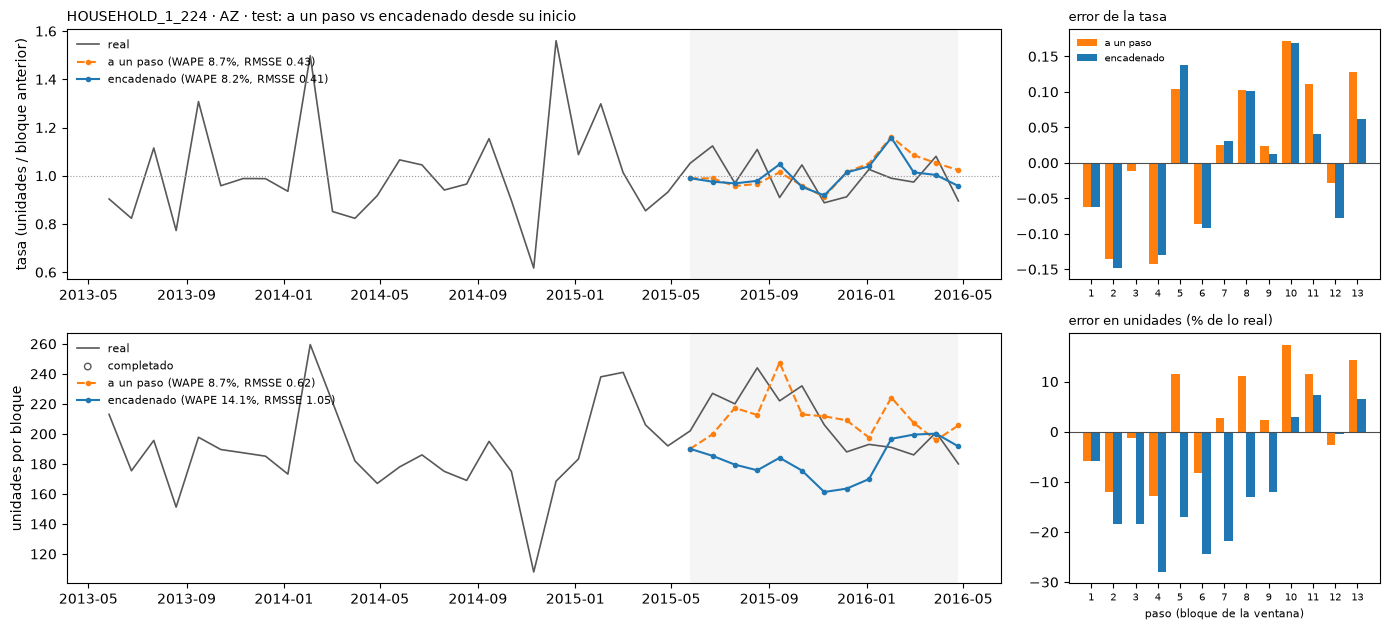

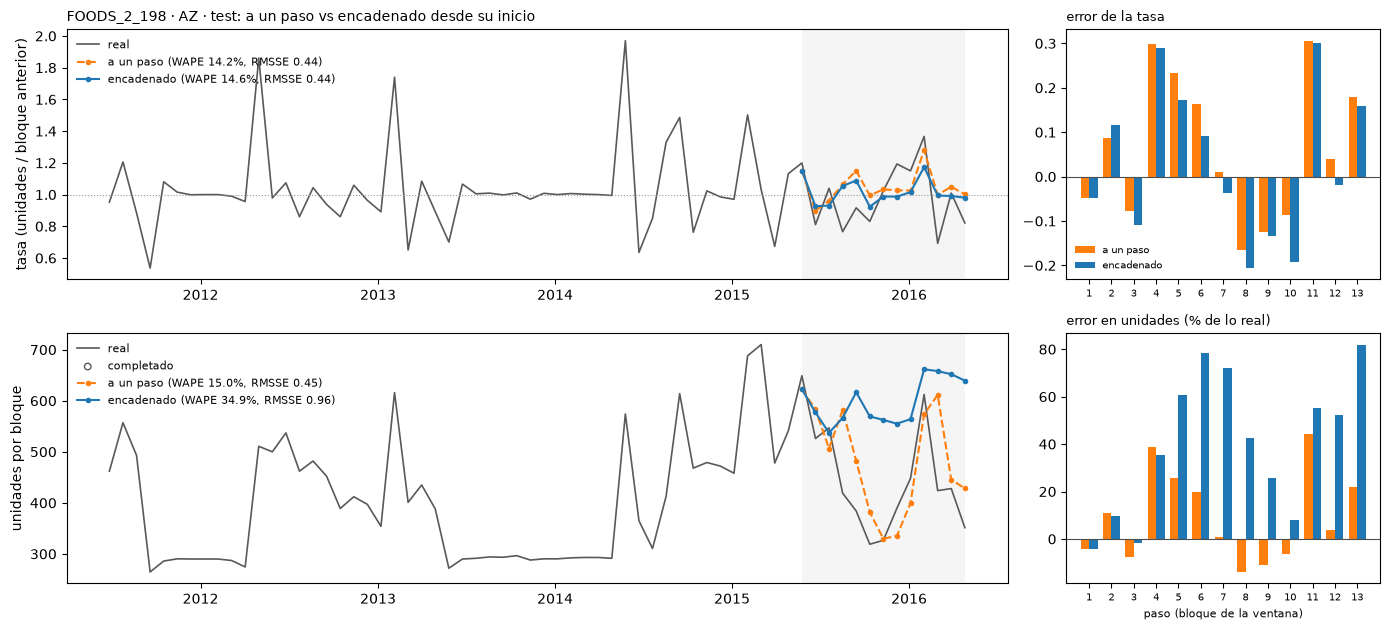

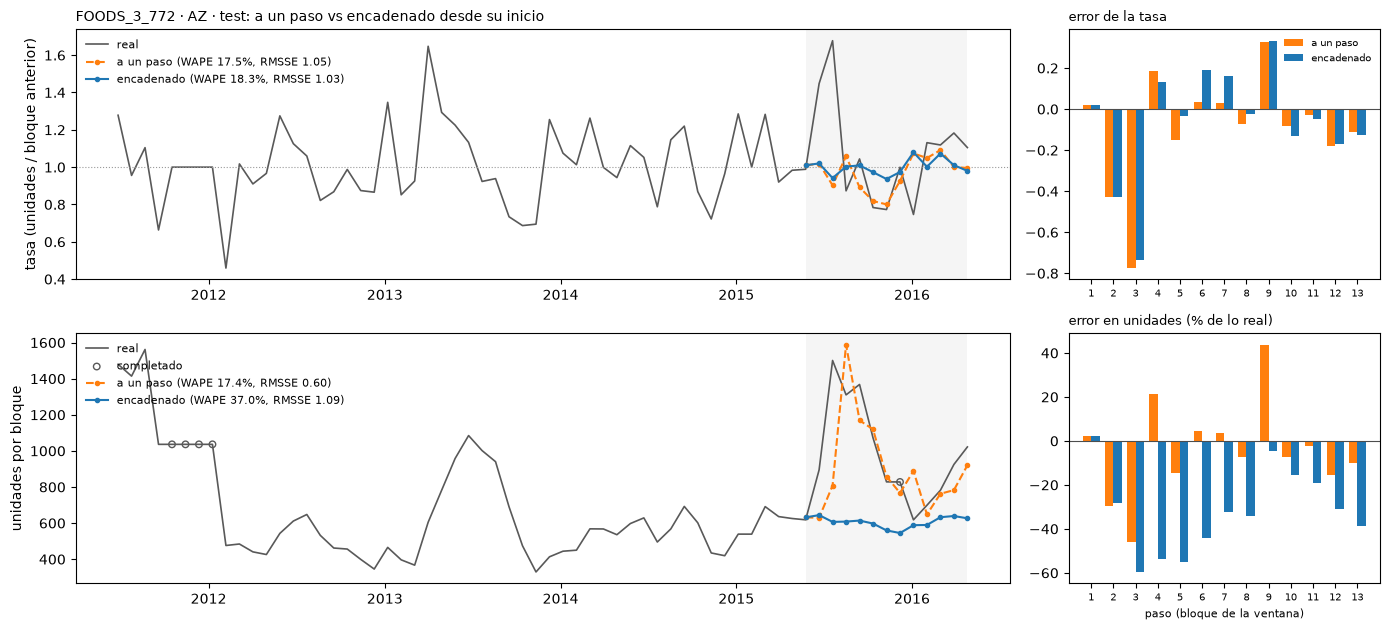

In [27]:
# Escala del RMSSE en tasas: misma definición que en unidades, con la tasa real de todo el train (como en el nb 04).
train_rows = test_data[test_data["split"] == "train"]
rate_scale = train_rows.groupby(train_rows["item_id"].astype(str))["ratio_raw"].apply(
    lambda r: seasonal_naive_scale(r.to_numpy(float), SNAIVE_M))

cell_of = forecasts.groupby("item_id")["cell"].first()
sample = {seg: cell_of[cell_of == seg].sample(SAMPLE_PER_SEGMENT, random_state=SEED).index.tolist() for seg in SEGMENTS}
for seg, ids in sample.items():
    for item in ids:
        fig = plot_forecast_item(test_data, forecasts, item, float(rate_scale[item]), float(rmsse_scale[item]),
                                 splits=("train", "test"), window_label="test")
        fig.tight_layout()
        plt.show()


In [28]:
for item, seg in cell_of.items():
    out_dir = FIG_DIR / seg
    out_dir.mkdir(parents=True, exist_ok=True)
    fig = plot_forecast_item(test_data, forecasts, item, float(rate_scale[item]), float(rmsse_scale[item]),
                             splits=("train", "test"), window_label="test")
    fig.tight_layout()
    fig.savefig(out_dir / f"{item}.png", dpi=FIG_DPI)
    plt.close(fig)


In [29]:
saved = {seg: sorted(p.stem for p in (FIG_DIR / seg).glob("*.png")) for seg in SEGMENTS}
for seg in SEGMENTS:
    assert saved[seg] == sorted(cell_of[cell_of == seg].index), seg   # cada artículo en la carpeta de su segmento
size_mb = sum(p.stat().st_size for p in FIG_DIR.rglob("*.png")) / 1e6
display(pd.Series({seg: len(v) for seg, v in saved.items()}, name="gráficos").rename_axis("segmento").to_frame())
print(f"{FIG_DIR}: {sum(map(len, saved.values()))} gráficos, {size_mb:.1f} MB")
display(pd.DataFrame(sample).rename_axis("muestra"))


,gráficos
segmento,
AX,191
AY,229
AZ,97


reports/figures/nb05_test: 517 gráficos, 79.7 MB


,AX,AY,AZ
muestra,,,
0,HOUSEHOLD_1_270,HOUSEHOLD_1_498,FOODS_3_491
1,FOODS_3_570,FOODS_3_300,FOODS_3_154
2,HOUSEHOLD_1_318,FOODS_1_110,HOUSEHOLD_1_224
3,FOODS_3_473,HOUSEHOLD_1_376,FOODS_2_198
4,FOODS_3_403,FOODS_1_187,FOODS_3_772


## Etapa 3 · Métricas globales y por artículo, aceptación y artículos para revisar

**Objetivo:** medir el test una sola vez (D6, D7, D8) y resumir el error global y por artículo para ver qué artículos se alejan de lo esperado (D11).
**Entradas:** `forecasts`, `rate_scale` y `cell_of` (Etapa 2); `rmsse_scale`, `weights`, `boosting_data`, `catboost`, `FEATURES`, `PARAMS` y `meta04` (Etapa 1).
**Salidas:**
- `summary`: WRMSSE y WAPE por nivel (tasas, unidades), forma (a un paso, encadenado, seasonal naive) y segmento, más el total; `by_step`: lo mismo por paso (total); `mae`: MAE por artículo, media y mediana.
- `accepted`: aceptación de la constitución.
- `item_metrics`: una fila por artículo y forma (a un paso, encadenado) con RMSSE, WAPE y MAE en unidades y en tasas, el RMSSE de su ventana de backtesting y las marcas para revisar.

**Decisión:**
- **Global (D6):** `item_errors` y `segment_errors`, las mismas funciones del 03d y del nb 04; pesos y escalas solo de train.
- **Aceptación (D7):** WRMSSE en unidades, total, de a un paso menor que el del seasonal naive. El encadenado se muestra frente al mismo seasonal naive, sin umbral.
- **Ventana de backtesting por artículo (D11):** a un paso, el pronóstico del 03c (cargado); encadenado, se repite el de la Etapa 2 del nb 04 (modelo del fold 1, mismos parámetros, determinista). Chequeo: el WRMSSE de a un paso en la ventana debe ser el del 03c (0,5062).
- **Por artículo, sin seasonal naive (usuario):** solo a un paso y encadenado.
- **Marcas (D11, Tukey, Q3 + 1,5·IQR, solo por arriba), dentro de cada forma y segmento:** (a) `outlier_segment`: RMSSE en unidades atípico; (b) `outlier_window`: cociente RMSSE test / RMSSE ventana atípico, calculado sobre el logaritmo del cociente, porque es multiplicativo (duplicar y reducir a la mitad quedan a la misma distancia de 1) y sin el log la cola larga marcaría de más. `review` = (a) o (b).
- **Gráficos:** los marcados en cualquiera de las dos formas, hasta 5 por segmento (los de mayor RMSSE en unidades), solo en pantalla, con el mismo gráfico de la Etapa 2.


In [30]:
from src.metrics import item_errors, segment_errors, tukey_outliers

KINDS = {"1step": "a un paso", "chain": "encadenado", "snaive": "seasonal naive"}
FORMS = ["a un paso", "encadenado"]   # por artículo, sin seasonal naive (usuario)
TUKEY_K = 1.5                         # regla clásica de Tukey (D11)
MAX_PLOTS = 5                         # marcados graficados por segmento (D11)


In [31]:
# Global: errores por artículo en los dos niveles y su agregado por segmento y por paso.
LEVELS = {"tasas": ("ratio", "ratio_raw", rate_scale), "unidades": ("units", "units", rmsse_scale)}
def level_errors(df):
    return {lvl: item_errors(df, [f"{p}_{k}" for k in KINDS], scale, actual_col=act).assign(
                candidate=lambda d: d["candidate"].str.split("_").str[-1].map(KINDS))
            for lvl, (p, act, scale) in LEVELS.items()}

errors = level_errors(forecasts)
summary = pd.concat({lvl: segment_errors(e, weights, cell_of) for lvl, e in errors.items()}, names=["nivel"])
by_step = pd.concat({(lvl, h): segment_errors(e, weights, cell_of).xs("total", level="segment")
                     for h, g in forecasts.groupby("step") for lvl, e in level_errors(g).items()}, names=["nivel", "step"])
mae = pd.concat({lvl: e.groupby("candidate")["mae"].agg(["mean", "median"]) for lvl, e in errors.items()}, names=["nivel"])

wrmsse_units = summary.loc["unidades", "wrmsse"].xs("total", level="segment")
accepted = bool(wrmsse_units["a un paso"] < wrmsse_units["seasonal naive"])


/tmp/ipykernel_150276/2242629038.py:14: PerformanceWarning: indexing past lexsort depth may impact performance.
  wrmsse_units = summary.loc["unidades", "wrmsse"].xs("total", level="segment")


In [32]:
for lvl, e in errors.items():
    assert len(e) == n_items * len(KINDS) and e["rmsse"].notna().all() and (e["n_blocks"] == N_TEST).all(), lvl
assert (rmsse_scale.reindex(cell_of.index) > 0).all() and (rate_scale.reindex(cell_of.index) > 0).all()
assert (summary.xs("total", level="segment")["n_items"] == n_items).all()
assert len(by_step) == len(LEVELS) * N_TEST * len(KINDS) and summary["wrmsse"].notna().all()

print("WRMSSE y WAPE en los 13 bloques de test, por segmento:")
display(summary[["wrmsse", "wape"]].unstack("candidate").round(4))
print(f"Aceptación (Principio VII): WRMSSE en unidades a un paso {wrmsse_units['a un paso']:.4f} "
      f"vs seasonal naive {wrmsse_units['seasonal naive']:.4f} → {'cumple' if accepted else 'NO cumple'}")
print(f"Encadenado (producción, sin umbral): {wrmsse_units['encadenado']:.4f}")
print("WRMSSE por paso (todos los artículos):")
display(by_step["wrmsse"].unstack("step").round(4))
print("MAE por artículo (tasas en tasa, unidades en unidades):")
display(mae.round(3))


WRMSSE y WAPE en los 13 bloques de test, por segmento:


wrmsse                                wape             \
candidate        a un paso encadenado seasonal naive a un paso encadenado   
nivel    segment                                                            
tasas    AY         0.5662     0.5858         0.8028    0.0971     0.0990   
         AX         0.7625     0.8064         0.9293    0.0809     0.0851   
         AZ         0.5720     0.5844         0.7785    0.1236     0.1249   
         total      0.6403     0.6676         0.8455    0.0962     0.0988   
unidades AY         0.4353     0.6544         0.8123    0.0970     0.1577   
         AX         0.6001     0.8775         0.9514    0.0746     0.1129   
         AZ         0.4252     0.7132         0.8341    0.1147     0.2064   
         total      0.4948     0.7479         0.8679    0.0930     0.1527   

                                 
candidate        seasonal naive  
nivel    segment                 
tasas    AY              0.1406  
         AX              0.1114  
         AZ              0.1700  
         total           0.1355  
unidades AY              0.1847  
         AX              0.1275  
         AZ              0.2726  
         total           0.1839

Aceptación (Principio VII): WRMSSE en unidades a un paso 0.4948 vs seasonal naive 0.8679 → cumple
Encadenado (producción, sin umbral): 0.7479
WRMSSE por paso (todos los artículos):


step                         1       2       3       4       5       6   \
nivel    candidate                                                        
tasas    a un paso       0.4965  0.4749  0.5136  0.4684  0.4711  0.4537   
         encadenado      0.4965  0.4677  0.5216  0.4840  0.5252  0.4706   
         seasonal naive  0.6901  0.6653  0.7050  0.6412  0.6561  0.6097   
unidades a un paso       0.3694  0.3656  0.4222  0.3773  0.3834  0.3594   
         encadenado      0.3694  0.4721  0.6293  0.6303  0.5581  0.5914   
         seasonal naive  0.7648  0.7617  0.8343  0.7496  0.6394  0.6885   

step                         7       8       9       10      11      12  \
nivel    candidate                                                        
tasas    a un paso       0.4704  0.4467  0.5950  0.5464  0.5161  0.5335   
         encadenado      0.4634  0.4411  0.6386  0.6156  0.4971  0.5532   
         seasonal naive  0.5909  0.6067  0.6171  0.7330  0.7019  0.7204   
unidades a un paso       0.3756  0.3503  0.4389  0.4002  0.4106  0.3948   
         encadenado      0.6141  0.6609  0.6937  0.6563  0.6937  0.7061   
         seasonal naive  0.6761  0.6680  0.7114  0.7196  0.7271  0.6969   

step                         13  
nivel    candidate               
tasas    a un paso       0.4965  
         encadenado      0.5241  
         seasonal naive  0.6544  
unidades a un paso       0.3824  
         encadenado      0.7249  
         seasonal naive  0.7465

MAE por artículo (tasas en tasa, unidades en unidades):


mean   median
nivel    candidate                       
tasas    a un paso         0.098    0.089
         encadenado        0.100    0.093
         seasonal naive    0.138    0.128
unidades a un paso        99.025   55.926
         encadenado      162.566   82.457
         seasonal naive  195.777  101.865

In [33]:
# Ventana de backtesting por artículo (D11): a un paso del 03c y encadenado como en el nb 04.
train_w1, _ = fold_masks(boosting_data, 1)
fit_w1 = train_w1 & boosting_data["ratio"].notna()
model_w1 = make_booster("catboost", PARAMS, meta04["seed"], N_THREADS)
model_w1.fit(boosting_data.loc[fit_w1, FEATURES], boosting_data.loc[fit_w1, "ratio"])
chain_w = recursive_ratio_forecast(boosting_data, model_w1, FEATURES, FE["target_lags"], FE["rolling_windows"],
                                   FE["rolling_stats"], first_fold=1, horizon=N_TEST)

window = (catboost["backtest"][["item_id", "block", "units", "units_prev", "pred"]].rename(columns={"pred": "units_1step"})
          .assign(item_id=lambda d: d["item_id"].astype(str))
          .merge(chain_w[["item_id", "block", "step", "ratio_hat"]], on=["item_id", "block"], validate="one_to_one")
          .sort_values(["item_id", "block"], ignore_index=True))
origin_w = window.loc[window["step"] == 1].set_index("item_id")["units_prev"].astype(float)
window["units_chain"] = chain_units(window, origin_w)
window_err = item_errors(window, ["units_1step", "units_chain"], rmsse_scale).assign(
    candidate=lambda d: d["candidate"].str.split("_").str[-1].map(KINDS))

# Por artículo y forma: test en los dos niveles, ventana y marcas.
METRICS = ["rmsse", "wape", "mae"]
pick = lambda e: e[e["candidate"].isin(FORMS)].set_index(["item_id", "candidate"])[METRICS]
item_metrics = (pick(errors["unidades"]).add_suffix("_units")
                .join(pick(errors["tasas"]).add_suffix("_ratio"))
                .join(window_err.set_index(["item_id", "candidate"])["rmsse"].rename("rmsse_units_window"))
                .rename_axis(["item_id", "form"]).reset_index())
item_metrics.insert(2, "cell", item_metrics["item_id"].map(cell_of))
item_metrics["test_vs_window"] = item_metrics["rmsse_units"] / item_metrics["rmsse_units_window"]
group = item_metrics["form"] + " · " + item_metrics["cell"]
item_metrics["outlier_segment"] = tukey_outliers(item_metrics["rmsse_units"], group, TUKEY_K)
item_metrics["outlier_window"] = tukey_outliers(np.log(item_metrics["test_vs_window"]), group, TUKEY_K)
item_metrics["review"] = item_metrics["outlier_segment"] | item_metrics["outlier_window"]


In [34]:
# Ventana: a un paso reproduce el 03c.
w_sum = segment_errors(window_err, weights, cell_of).xs("total", level="segment")["wrmsse"]
assert np.isclose(w_sum["a un paso"], catboost["meta"]["wrmsse"]), w_sum["a un paso"]
assert len(window) == n_items * N_TEST and window[["units_1step", "units_chain"]].notna().all().all()

assert len(item_metrics) == n_items * len(FORMS) and not item_metrics.duplicated(["item_id", "form"]).any()
assert item_metrics.drop(columns=["outlier_segment", "outlier_window", "review"]).notna().all().all()
assert (item_metrics["rmsse_units_window"] > 0).all()

print(f"ventana: WRMSSE en unidades a un paso {w_sum['a un paso']:.4f} (03c: {catboost['meta']['wrmsse']:.4f}), "
      f"encadenado {w_sum['encadenado']:.4f}")
print("Artículos para revisar, por forma y segmento:")
display(item_metrics.groupby(["form", "cell"])[["outlier_segment", "outlier_window", "review"]].sum()
        .assign(articulos=item_metrics.groupby(["form", "cell"]).size()))
print("RMSSE en unidades por artículo, por forma y segmento:")
display(item_metrics.groupby(["form", "cell"])["rmsse_units"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3))
flagged = item_metrics[item_metrics["review"]].sort_values(["form", "cell", "rmsse_units"], ascending=[True, True, False])
display(flagged[["item_id", "form", "cell", "rmsse_units", "wape_units", "rmsse_units_window", "test_vs_window",
                 "outlier_segment", "outlier_window"]].round(3))


ventana: WRMSSE en unidades a un paso 0.5062 (03c: 0.5062), encadenado 0.7418
Artículos para revisar, por forma y segmento:


outlier_segment  outlier_window  review  articulos
form       cell                                                    
a un paso  AX                  6               3       6        191
           AY                 10               6      11        229
           AZ                  4               2       5         97
encadenado AX                  9               1       9        191
           AY                 12               1      12        229
           AZ                  6               2       7         97

RMSSE en unidades por artículo, por forma y segmento:


count   mean    std    min    25%    50%    75%    90%    max
form       cell                                                               
a un paso  AX    191.0  0.579  0.252  0.194  0.403  0.525  0.689  0.925  1.662
           AY    229.0  0.464  0.283  0.075  0.301  0.407  0.573  0.711  2.223
           AZ     97.0  0.405  0.326  0.045  0.165  0.306  0.551  0.794  1.853
encadenado AX    191.0  0.842  0.479  0.203  0.531  0.680  1.027  1.555  2.830
           AY    229.0  0.715  0.619  0.066  0.388  0.557  0.870  1.349  7.167
           AZ     97.0  0.683  0.583  0.050  0.270  0.491  0.904  1.552  3.056

,item_id,form,cell,rmsse_units,wape_units,rmsse_units_window,test_vs_window,outlier_segment,outlier_window
114,FOODS_2_131,a un paso,AX,1.662,0.129,0.621,2.674,True,True
312,FOODS_3_252,a un paso,AX,1.639,0.098,0.981,1.671,True,False
192,FOODS_2_349,a un paso,AX,1.344,0.099,0.618,2.176,True,False
774,HOUSEHOLD_1_109,a un paso,AX,1.308,0.113,0.356,3.670,True,True
798,HOUSEHOLD_1_162,a un paso,AX,1.272,0.119,0.602,2.113,True,False
200,FOODS_2_371,a un paso,AX,1.250,0.070,0.319,3.916,True,True
944,HOUSEHOLD_1_441,a un paso,AY,2.223,0.217,0.424,5.243,True,True
734,HOUSEHOLD_1_045,a un paso,AY,2.210,0.189,0.741,2.983,True,True
392,FOODS_3_404,a un paso,AY,1.528,0.157,0.484,3.157,True,True
710,HOUSEHOLD_1_005,a un paso,AY,1.466,0.215,0.843,1.739,True,False


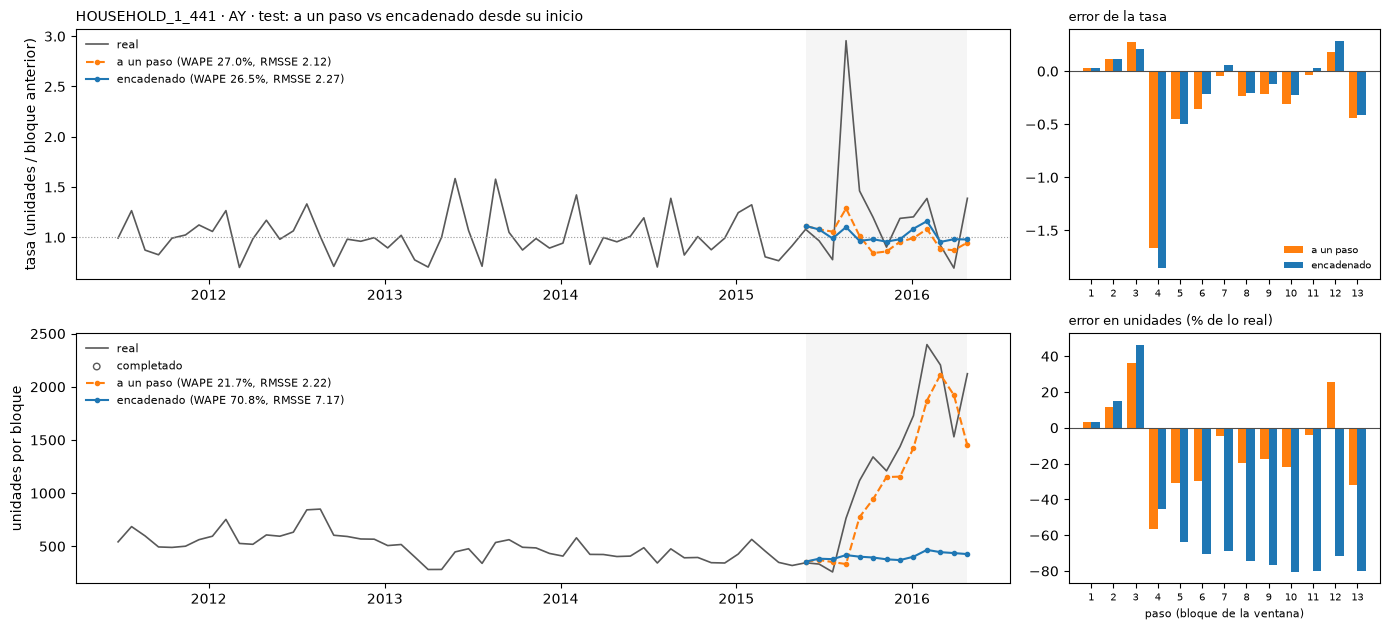

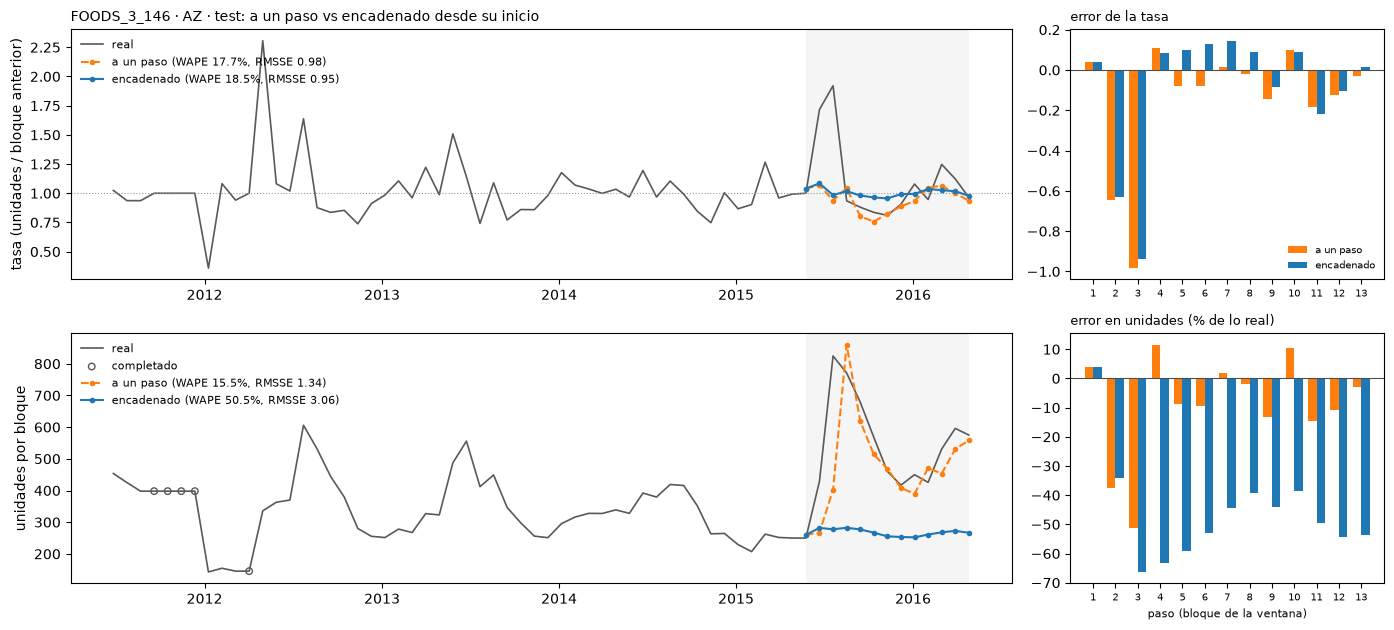

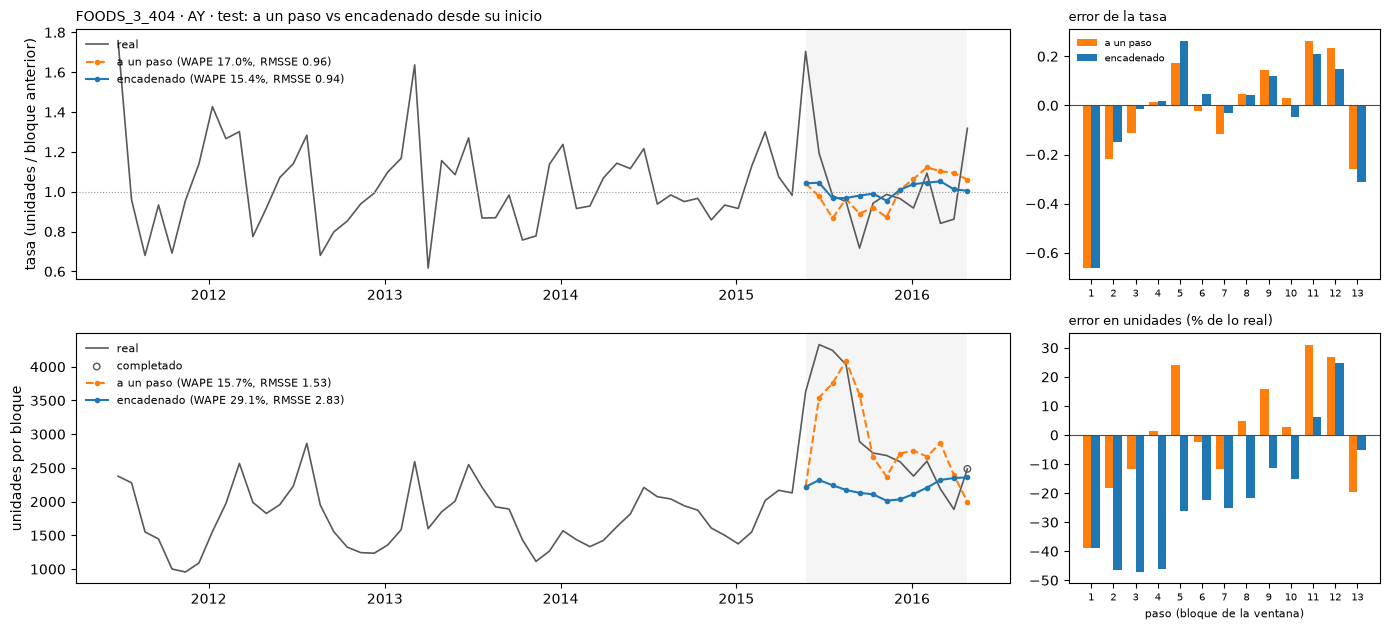

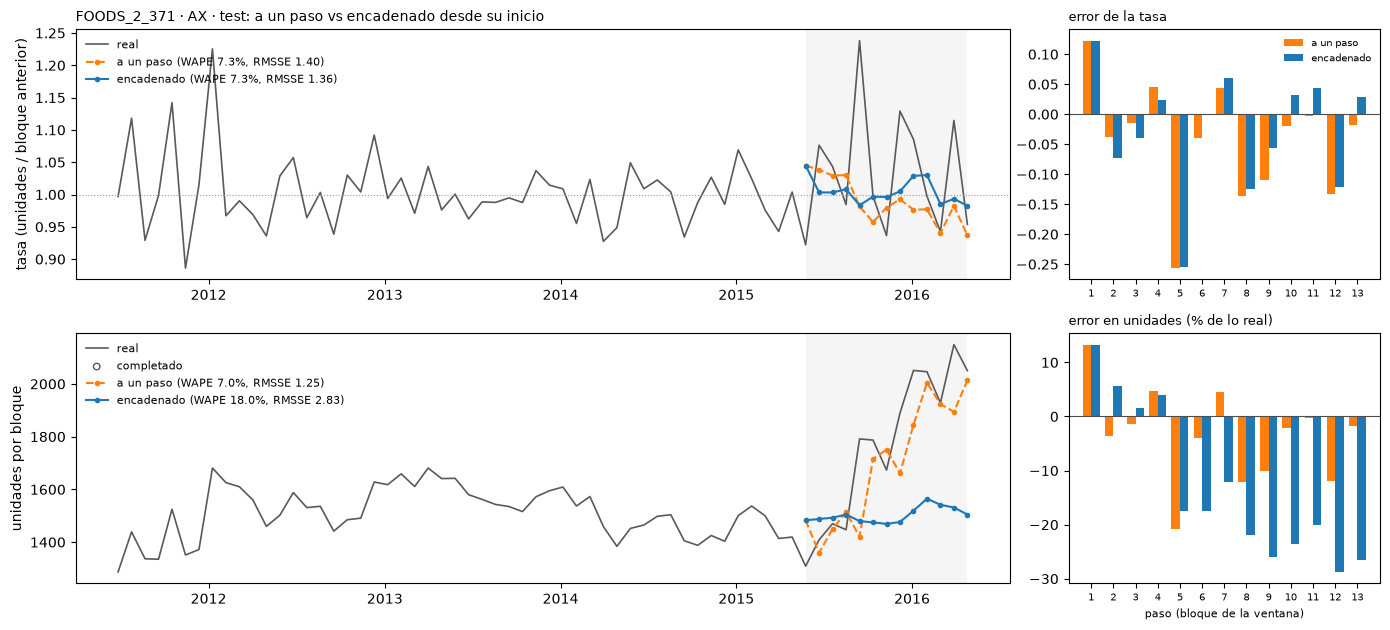

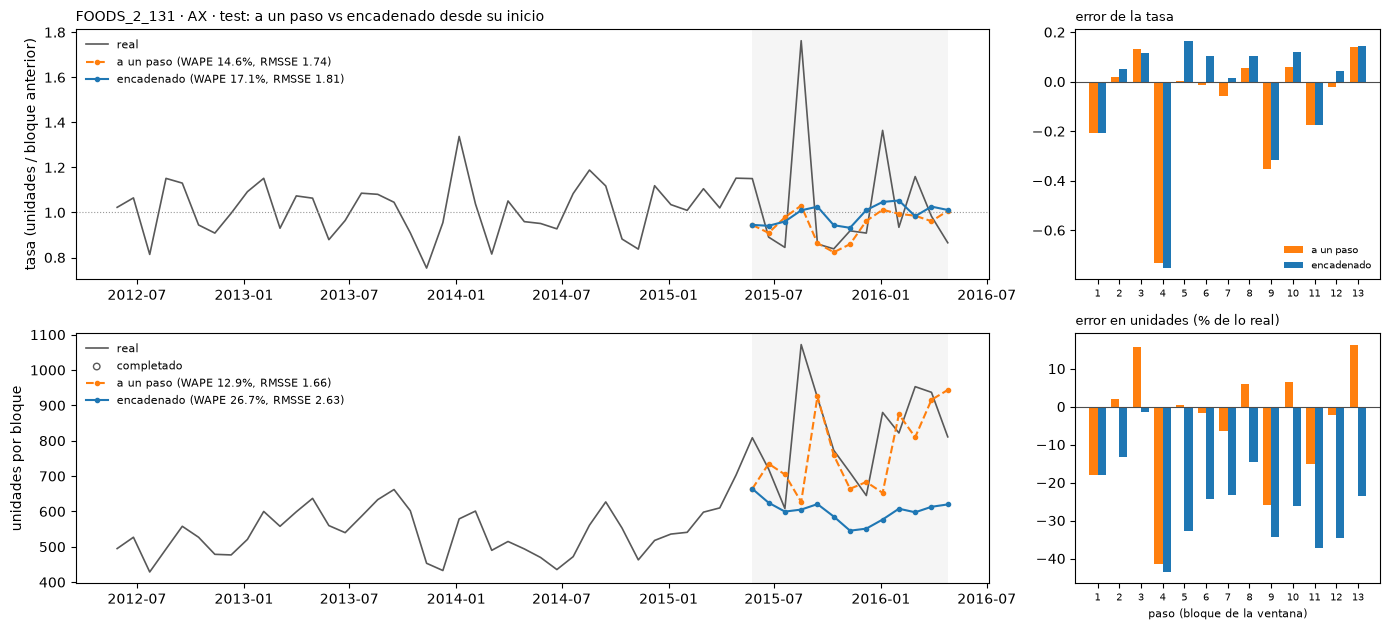

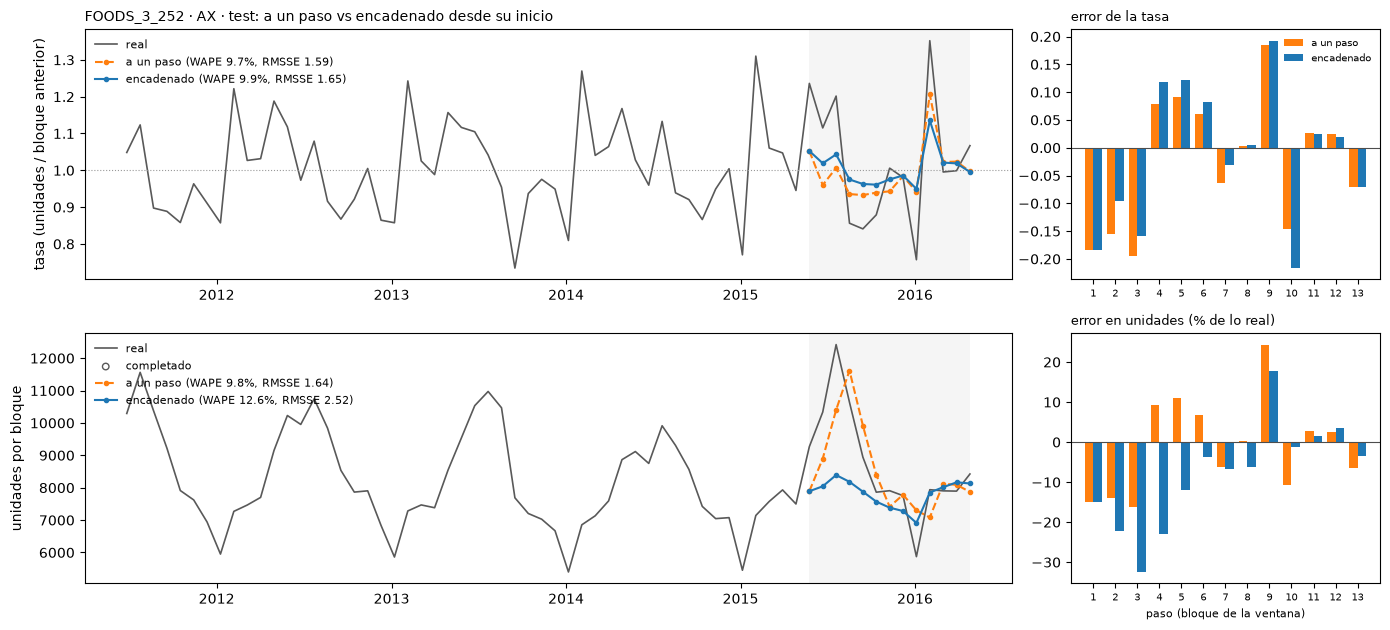

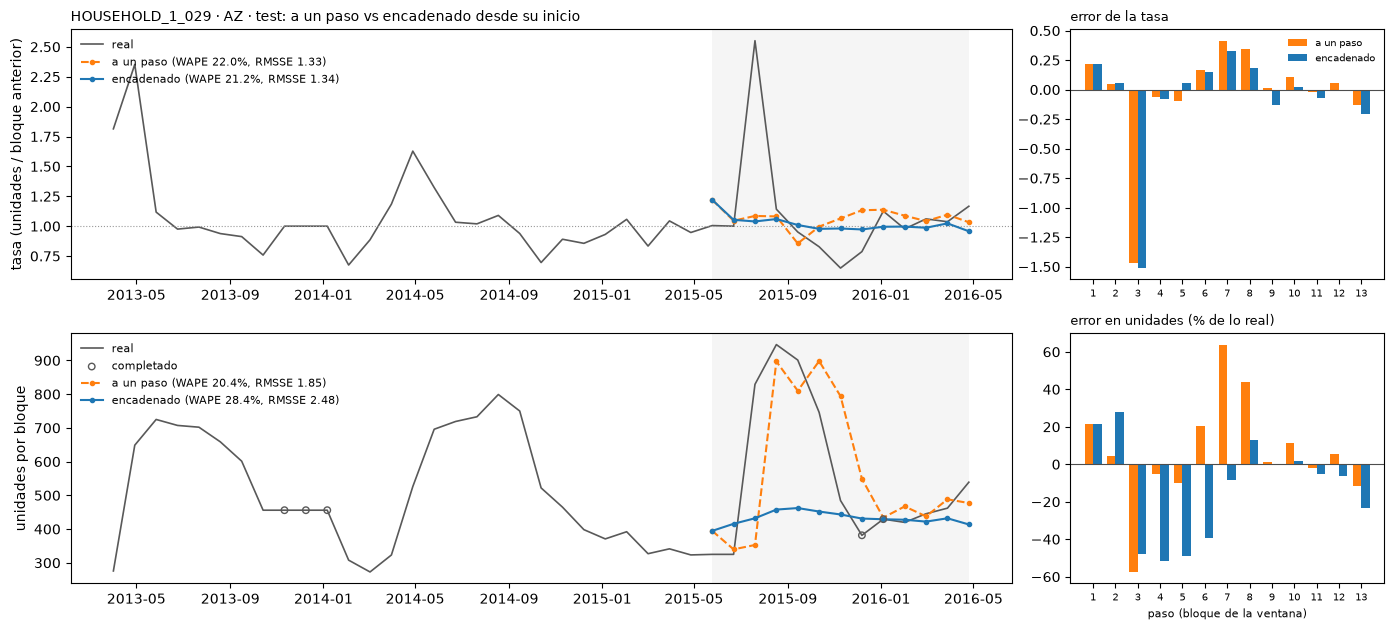

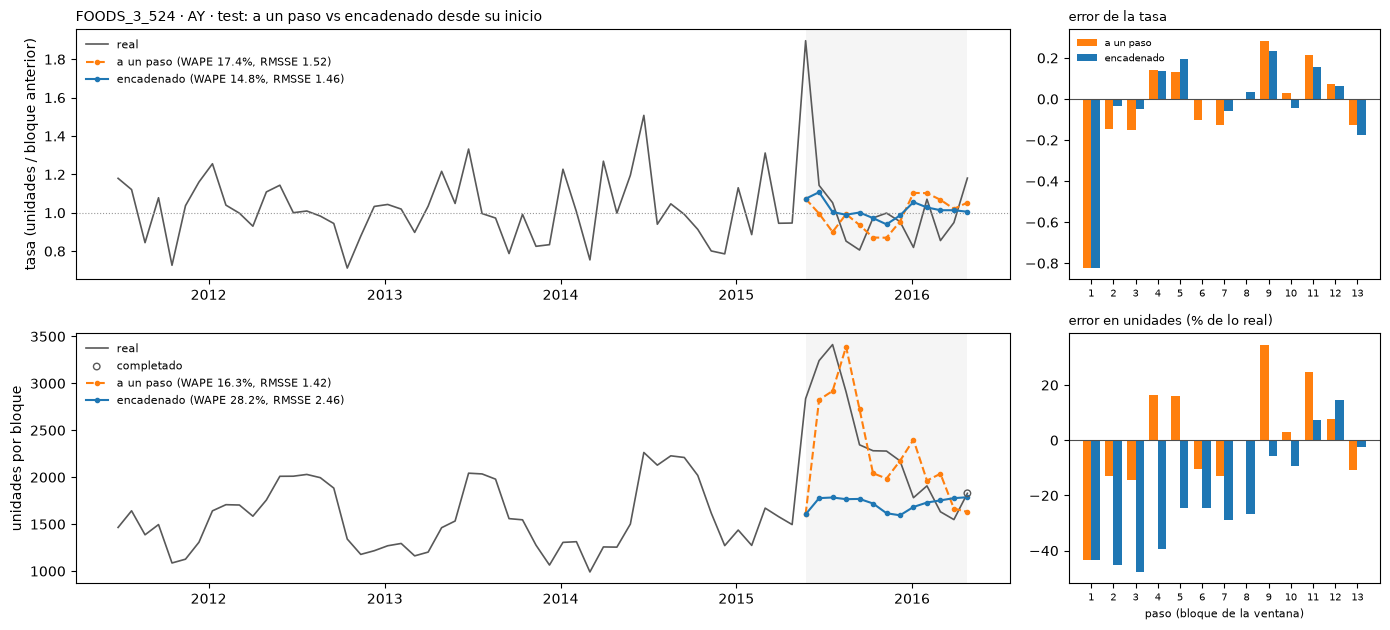

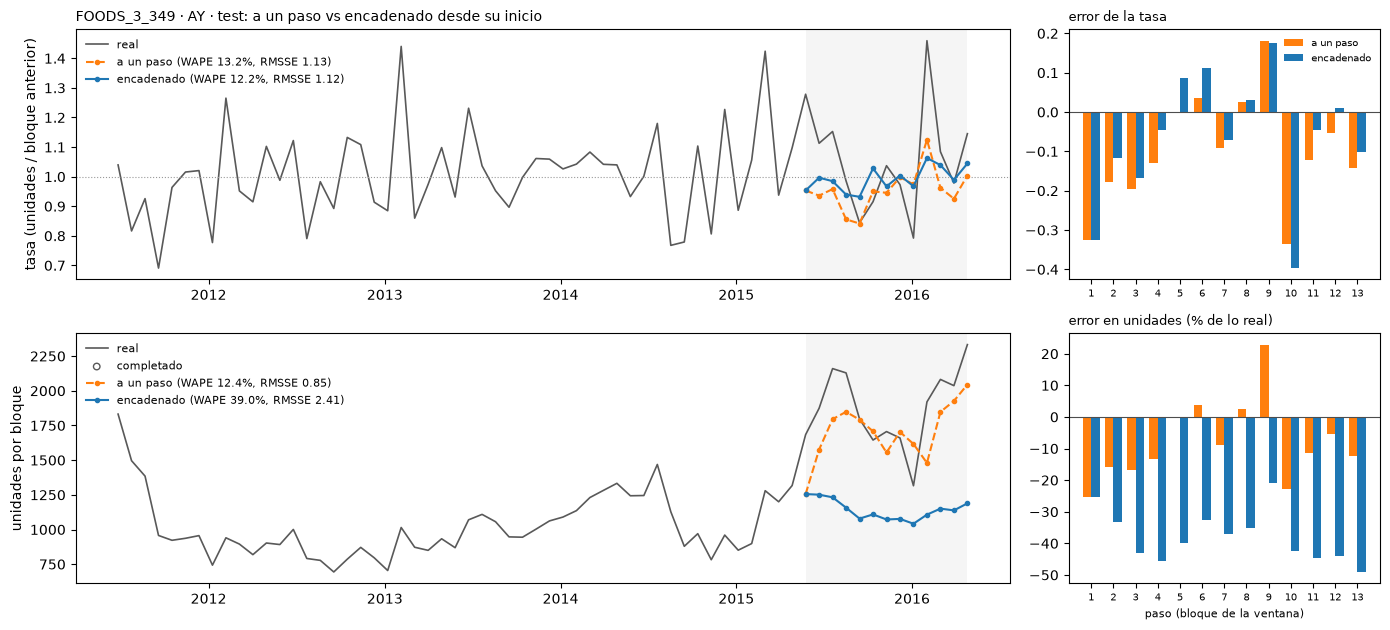

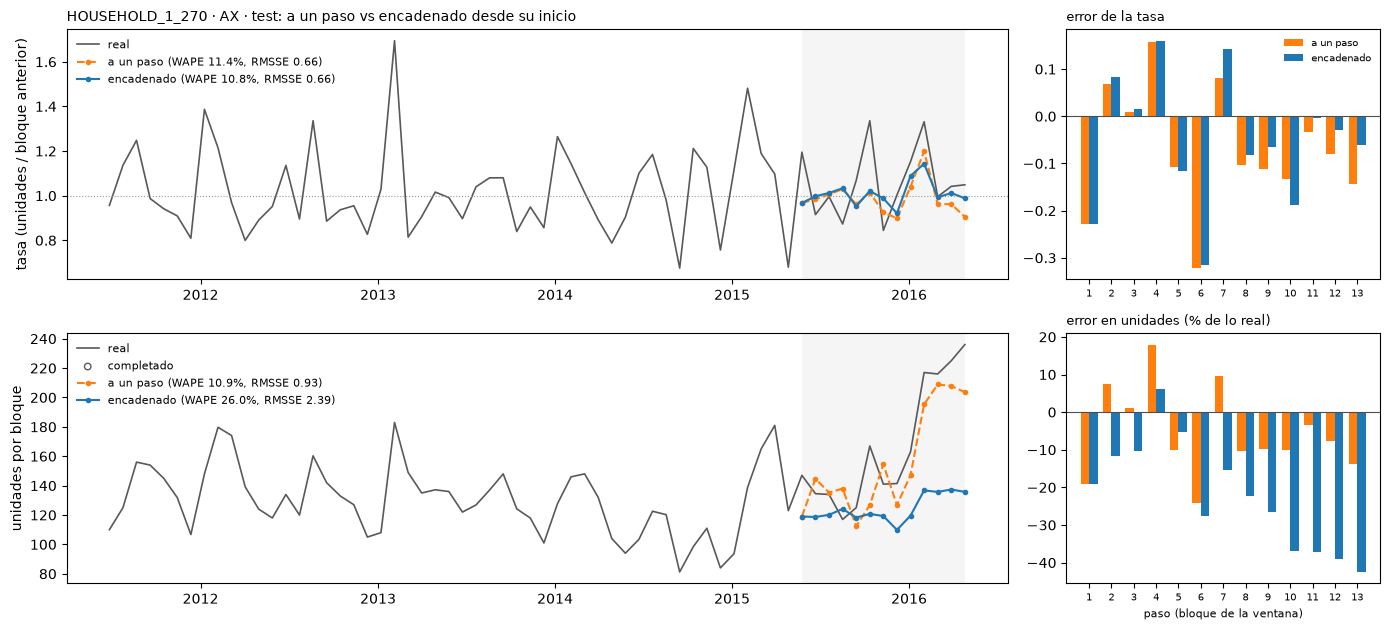

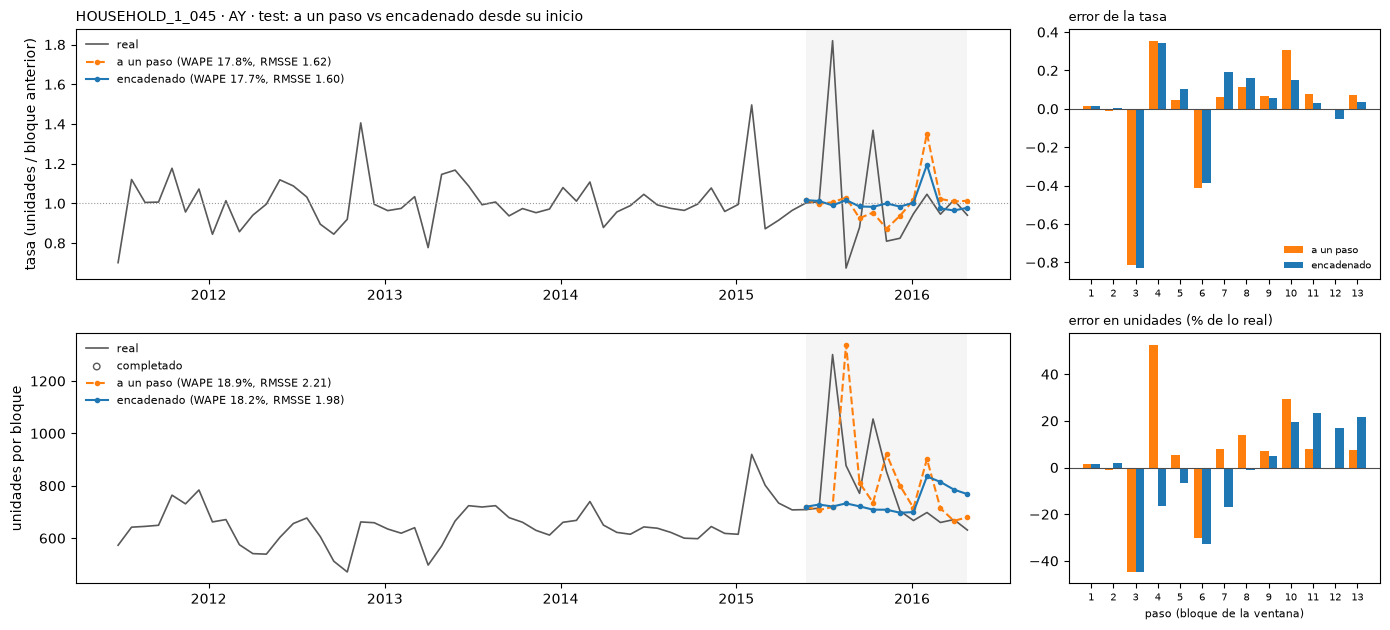

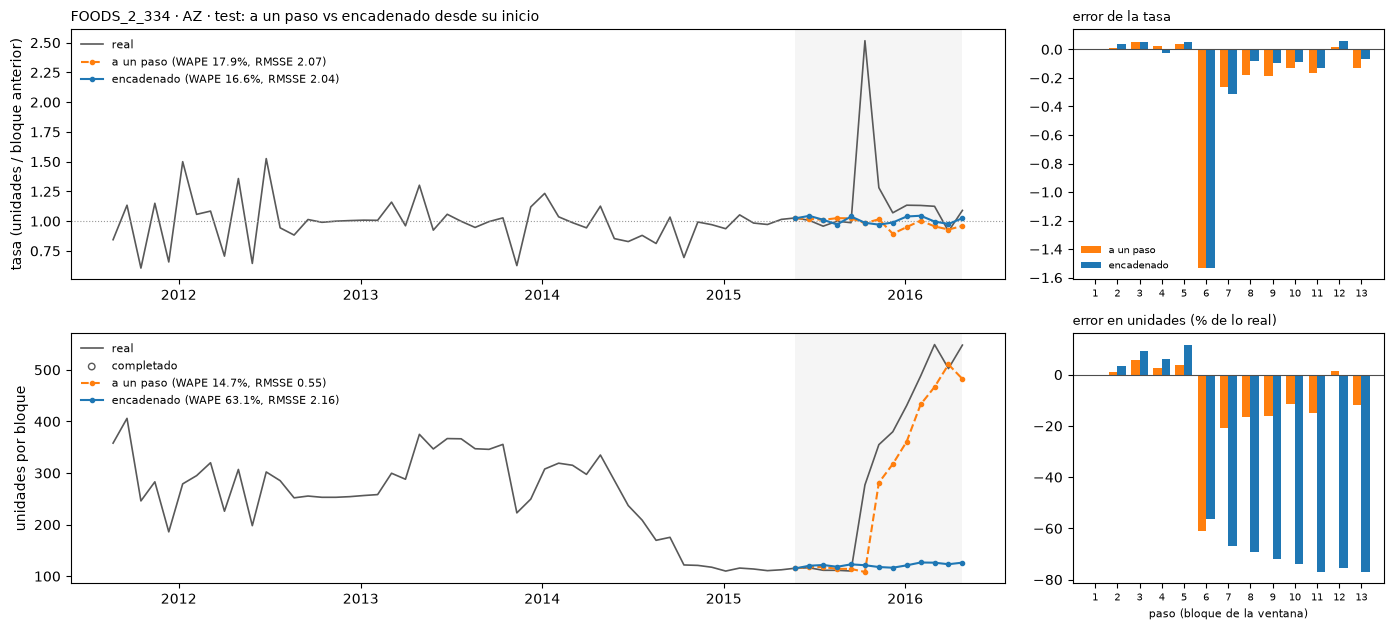

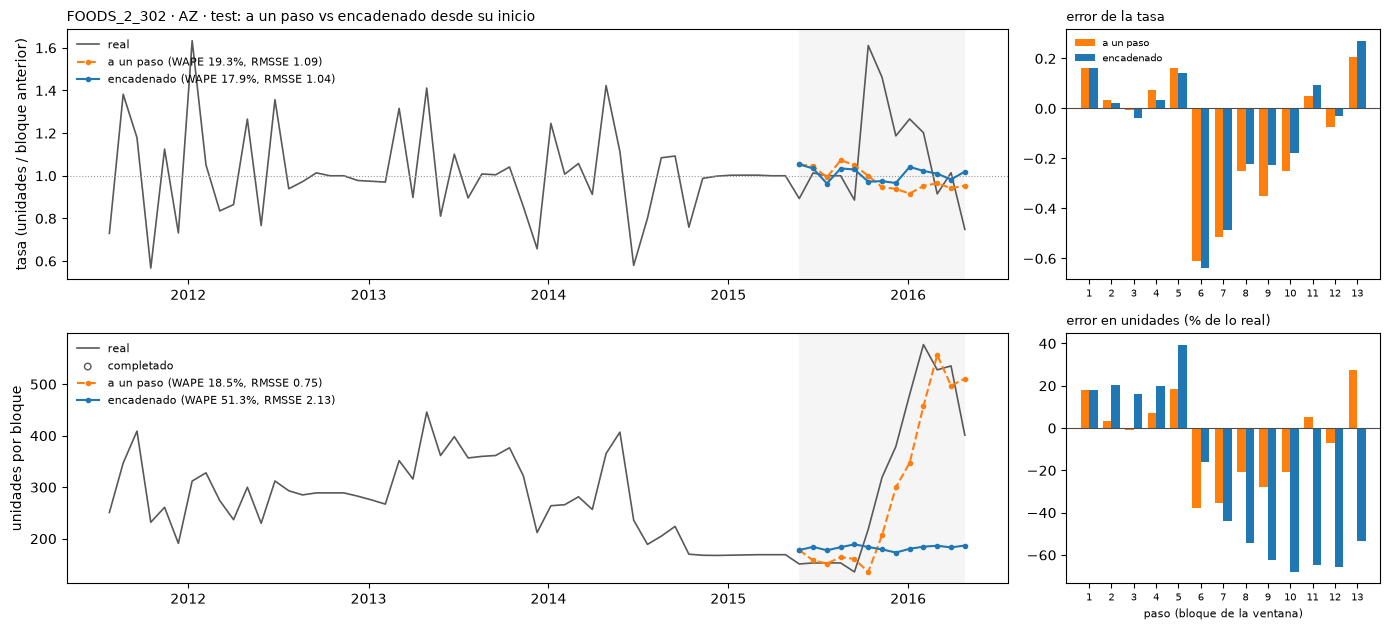

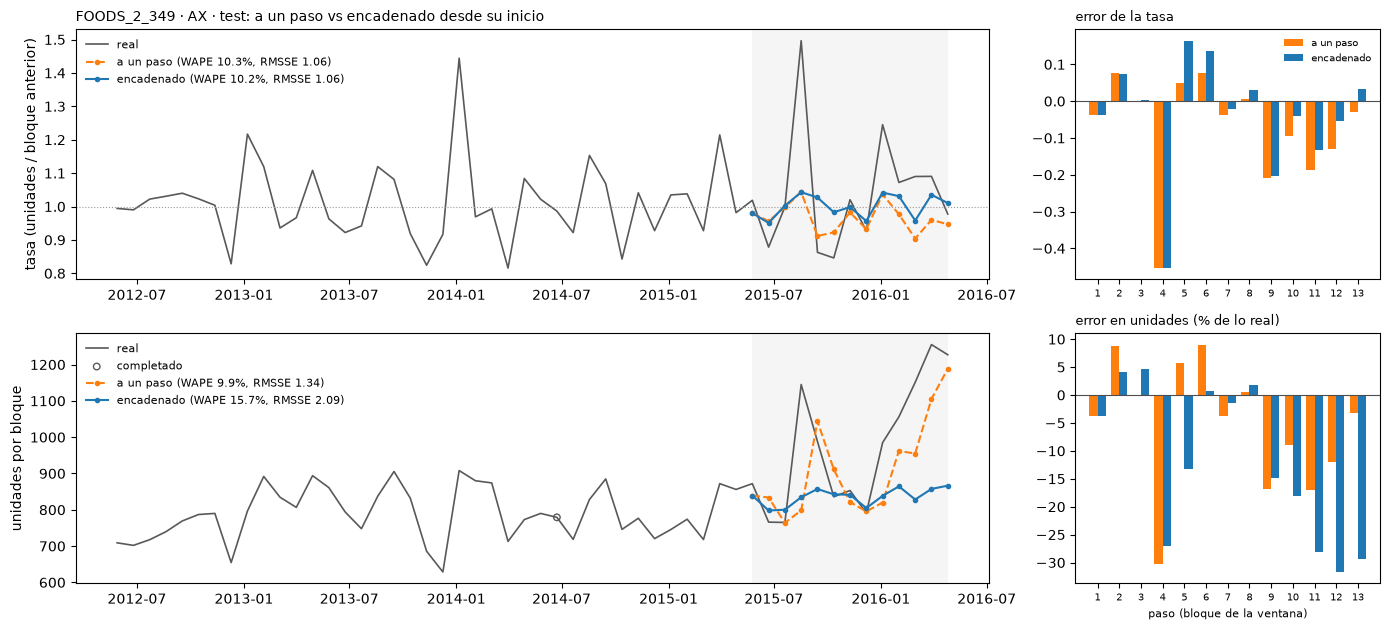

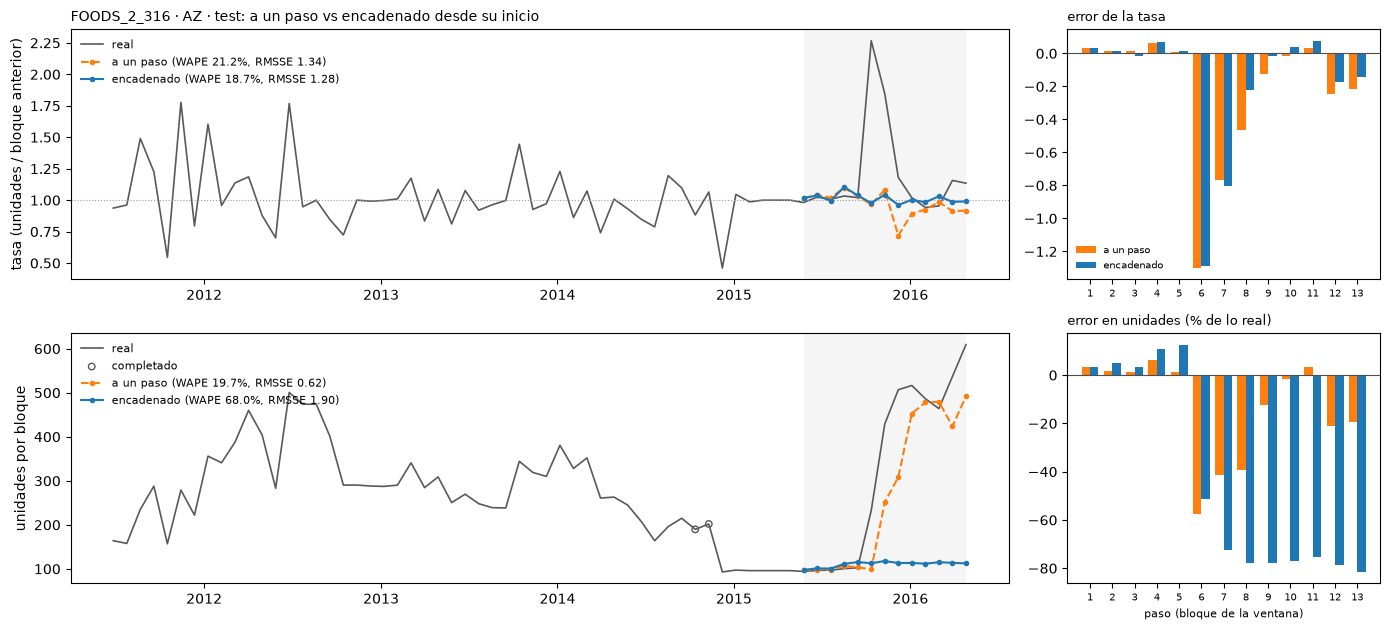

,cell,rmsse
item_id,,
HOUSEHOLD_1_441,AY,7.167
FOODS_3_146,AZ,3.056
FOODS_3_404,AY,2.833
FOODS_2_371,AX,2.830
FOODS_2_131,AX,2.630
FOODS_3_252,AX,2.525
HOUSEHOLD_1_029,AZ,2.481
FOODS_3_524,AY,2.463
FOODS_3_349,AY,2.414


In [35]:
# Gráficos de los marcados: hasta 5 por segmento, los de mayor RMSSE en unidades (cualquier forma).
top = (flagged.groupby("item_id").agg(cell=("cell", "first"), rmsse=("rmsse_units", "max"))
       .sort_values("rmsse", ascending=False).groupby("cell").head(MAX_PLOTS))
for item in top.index:
    fig = plot_forecast_item(test_data, forecasts, item, float(rate_scale[item]), float(rmsse_scale[item]),
                             splits=("train", "test"), window_label="test")
    fig.tight_layout()
    plt.show()
display(top.round(3))


## Etapa 4 · Guardado y cierre

**Objetivo:** dejar en disco la única medición del test para que el nb 06 la cargue sin volver a tocarlo (D8, D9).
**Entradas:** `forecasts` (Etapa 2); `summary`, `by_step`, `mae`, `accepted` e `item_metrics` (Etapa 3).
**Salidas:** `data/interim/nb05_test/` con:
- `forecasts.parquet`: una fila por artículo y bloque de test con lo real y los pronósticos a un paso, encadenado y seasonal naive, en tasas y en unidades.
- `metrics.parquet`: WRMSSE, WAPE y número de artículos por nivel, forma y segmento; `step` vacío = los 13 bloques juntos, 1–13 = por paso (solo total).
- `mae.parquet`: MAE por artículo, media y mediana, por nivel y forma.
- `item_metrics.parquet`: errores por artículo y forma con su ventana y las marcas para revisar.
- `manifest.json`: aceptación, WRMSSE de la aceptación, origen (03b, 03c, nb 04), semilla, artículos, bloques, k de Tukey y versiones.

**Decisión:** `save_tables` (Parquet + manifiesto) con candado: si lo guardado es igual no escribe; si es distinto se detiene salvo `OVERWRITE = True`. **Chequeo:** lo leído de disco es igual a lo que está en memoria.


In [36]:
from src.data import load_tables, save_tables


In [37]:
metrics = pd.concat([
    summary.reset_index().assign(step=pd.NA),
    by_step.reset_index().assign(segment="total"),
], ignore_index=True).rename(columns={"candidate": "form"})
metrics["step"] = metrics["step"].astype("Int64")
metrics = metrics[["nivel", "form", "segment", "step", "n_items", "wrmsse", "wape"]]

out_manifest = {
    "accepted": accepted,
    "wrmsse_units": {k: float(v) for k, v in wrmsse_units.items()},
    "source": {"nb03b_saved_at": manifest["saved_at"], "nb03c_trial": catboost["meta"]["trial"],
               "nb04_saved_at": meta04["saved_at"]},
    "seed": SEED, "n_items": int(n_items), "n_test": N_TEST, "tukey_k": TUKEY_K,
    "versions": {"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}},
}
tables = {"forecasts": forecasts, "metrics": metrics, "mae": mae.reset_index(), "item_metrics": item_metrics}
saved = save_tables(OUT_DIR, tables, out_manifest, overwrite=OVERWRITE)


In [38]:
loaded, loaded_manifest = load_tables(OUT_DIR)
assert set(loaded) == set(tables)
for name, df in tables.items():
    pd.testing.assert_frame_equal(loaded[name].reset_index(drop=True), df.reset_index(drop=True), check_dtype=False)
assert loaded_manifest["accepted"] == accepted and loaded_manifest["n_items"] == n_items
assert len(metrics) == len(summary) + len(by_step) and metrics["wrmsse"].notna().all()

display(pd.DataFrame({"archivo": [str(p) for p in saved], "KB": [round(p.stat().st_size / 1024, 1) for p in saved]}))
print(f"guardado: {loaded_manifest['saved_at']}")


,archivo,KB
0,data/interim/nb05_test/forecasts.parquet,493.4
1,data/interim/nb05_test/metrics.parquet,6.2
2,data/interim/nb05_test/mae.parquet,2.8
3,data/interim/nb05_test/item_metrics.parquet,88.6
4,data/interim/nb05_test/manifest.json,0.8


guardado: 2026-11-10T16:39:25


## Cierre

**Qué se midió:** el CatBoost global del nb 04 en los 13 bloques de test de los 517 artículos, una sola vez, de dos formas: a un paso (13 orígenes con reentrenamiento, el régimen de la constitución) y encadenado 13 bloques desde el último bloque de train (el uso en producción), frente al seasonal naive.

**Dónde está:** el resumen de la celda siguiente sale de lo guardado; el detalle, en la Etapa 3 y en `data/interim/nb05_test/`. Los gráficos de los 517 artículos están en `reports/figures/nb05_test/<segmento>/`.

**Para el nb 06:** carga `data/interim/nb05_test/` (y, si lo necesita, el modelo de `models/nb04_catboost/`); no vuelve a pronosticar ni a medir el test.


In [39]:
units_total = metrics[(metrics["nivel"] == "unidades") & (metrics["segment"] == "total") & metrics["step"].isna()].set_index("form")
print(f"Aceptación (a un paso < seasonal naive, WRMSSE en unidades): {'cumple' if loaded_manifest['accepted'] else 'NO cumple'}")
display(units_total[["wrmsse", "wape"]].round(4))
n_review = item_metrics[item_metrics["review"]].groupby("form")["item_id"].nunique()
print("Artículos para revisar:", ", ".join(f"{form} {n}" for form, n in n_review.items()) or "ninguno")


Aceptación (a un paso < seasonal naive, WRMSSE en unidades): cumple


,wrmsse,wape
form,,
a un paso,0.4948,0.0930
encadenado,0.7479,0.1527
seasonal naive,0.8679,0.1839


Artículos para revisar: a un paso 22, encadenado 28
